<a href="https://colab.research.google.com/github/sofilukash/analysis_of_cyber_incidents_using_ml/blob/main/lsh_ai_vs_real_images_lab7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 7
## Метод чутливого до розташування хешування (Locality Sensitive Hashing, LSH) в системах машинного навчання

**Мета:** реалізувати метод LSH для пошуку схожих зображень та їх класифікації (реальне фото / зображення, згенероване штучним інтелектом), порівняти його з іншим раніше реалізованим алгоритмом (kNN, SVM) та дослідити, як точність і швидкість LSH залежать від його параметрів та особливостей даних.

**Завдання:** застосувати LSH до одного з датасетів Kaggle (розділ *image classification*), порівняти з результатами класифікації будь-яким іншим із раніше реалізованих алгоритмів.

**Датасет:** AI vs Real Images ([Kaggle: rhythmghai/ai-vs-real-images-dataset](https://www.kaggle.com/datasets/rhythmghai/ai-vs-real-images-dataset)) — 995 зображень: 745 реальних фотографій (JPEG, ≈ 1 080 px) та 250 зображень, згенерованих штучним інтелектом (PNG, 512×512), п'яти категорій сцен (тварини, місто, їжа, природа, люди). Основна мітка — реальне / згенероване (виявлення згенерованого контенту актуальне для кібербезпеки: дезінформація, підроблені фото, шахрайство); додатково використовується категорія сцени. Для вилучення ознак застосовано попередньо навчену нейромережу ResNet-50, а LSH реалізовано власноруч.

**План роботи:**
1. Завантаження даних
2. Первинний аналіз даних
3. Підготовка даних: вирівнювання зображень, ознаки, поділ на вибірки
4. Реалізація алгоритму LSH
5. Базові моделі
6. Залежність точності й швидкості від параметрів LSH та особливостей даних: підготовка векторів, кількість бітів, бакети, кількість сусідів, представлення зображень, артефакт формату файлів, штучні копії та витік даних, друга мітка (категорія сцени), розмір бази, зведення
7. LSH для пошуку майже дублікатів
8. Підбір параметрів та підсумкова модель
9. Порівняння з kNN та SVM
10. Переваги та недоліки LSH
11. Загальні висновки

## 0. Імпорт бібліотек

In [1]:
import os, io, glob, time, zipfile, hashlib, warnings, itertools, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from PIL import Image
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

from skimage.color import rgb2gray, rgb2hsv
from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## 1. Завантаження даних
Папки `real_dataset` і `Ai_generated_dataset` беруться з поточної директорії; якщо їх немає — датасет завантажується з Kaggle через `kagglehub`; якщо й це не вдалося — з'явиться вікно для ручного завантаження ZIP-архіву (≈ 250 МБ). Для вилучення ознак із зображень використовується попередньо навчена нейромережа ResNet-50 у форматі ONNX (≈ 100 МБ), яка завантажується з GitHub (п. 3).

In [2]:
IMG_EXT = (".jpg", ".jpeg", ".png")
SOURCES = {"real_dataset": "real", "ai_generated_dataset": "ai"}       # назви папок → мітка джерела

def class_root(folder):
    """Знаходить папку, у якій лежать підпапки real_dataset та Ai_generated_dataset."""
    for path, dirs, _ in os.walk(folder):
        if set(SOURCES) <= {d.lower() for d in dirs}:
            return path

def find_dataset():
    if class_root("."):
        return class_root(".")
    try:
        try:
            import kagglehub
        except ImportError:
            import subprocess, sys
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
            import kagglehub
        root = class_root(kagglehub.dataset_download("rhythmghai/ai-vs-real-images-dataset"))
        if root:
            return root
    except Exception as e:
        print("Автозавантаження з Kaggle не вдалося:", e)
    from google.colab import files
    print("Завантажте ZIP-архів датасету вручну:")
    zip_name = next(iter(files.upload()))
    zipfile.ZipFile(zip_name).extractall("dataset_images")
    return class_root("dataset_images")

ROOT = find_dataset()
rows = []
for p in sorted(glob.glob(os.path.join(ROOT, "*", "*", "*"))):
    parts = p.split(os.sep)
    if parts[-3].lower() in SOURCES and p.lower().endswith(IMG_EXT):
        rows.append({"path": p, "source": SOURCES[parts[-3].lower()], "category": parts[-2].lower()})
meta = pd.DataFrame(rows)
print("Папка з даними:", ROOT, "| зображень:", len(meta), "| категорій:", meta["category"].nunique())

100%|██████████| 237M/237M [00:14<00:00, 17.7MB/s]

Extracting files...


Папка з даними: /root/.cache/kagglehub/datasets/rhythmghai/ai-vs-real-images-dataset/versions/1 | зображень: 995 | категорій: 5


## 2. Первинний аналіз даних
Дивимось на розподіл зображень за джерелом (реальне / згенероване) і категорією, на формат, розмір і пропорції зображень та розмір файлів, перевіряємо точні дублікати й розглядаємо приклади. Особливу увагу приділяємо **технічним відмінностям** між двома джерелами: якщо вони є, клас можна вгадати, не аналізуючи зміст зображення.

In [3]:
def center_square(im):
    """Центральний квадрат зображення."""
    w, h = im.size
    s = min(w, h)
    return im.crop(((w - s) // 2, (h - s) // 2, (w - s) // 2 + s, (h - s) // 2 + s))

def file_info(p):
    with Image.open(p) as im:                       # відкриваємо лише заголовок, без декодування пікселів
        return im.size[0], im.size[1], im.mode, im.format
meta[["width", "height", "mode", "format"]] = [file_info(p) for p in meta["path"]]
meta["bytes"] = [os.path.getsize(p) for p in meta["path"]]
meta["aspect"] = meta["width"] / meta["height"]
meta["md5"] = [hashlib.md5(open(p, "rb").read()).hexdigest() for p in meta["path"]]

print("Зображень за категорією та джерелом:")
display(pd.crosstab(meta["category"], meta["source"], margins=True))
tech = meta.groupby("source").agg(зображень=("path", "size"), формат=("format", lambda s: ", ".join(sorted(set(s)))), режим=("mode", lambda s: ", ".join(sorted(set(s)))),
                                  ширина_медіана=("width", "median"), висота_медіана=("height", "median"), пропорція_медіана=("aspect", "median"),
                                  розмір_файлу_КБ_медіана=("bytes", lambda s: s.median() / 1024))
tech["частка 512×512"] = meta.assign(sq=(meta["width"] == 512) & (meta["height"] == 512)).groupby("source")["sq"].mean()
print("Технічні характеристики файлів за джерелом:")
display(tech.round(2).T)
print("Базовий рівень (завжди прогнозувати найчастіший клас): реальне/згенероване {:.3f}, категорія {:.3f}".format(
    meta["source"].value_counts(normalize=True).max(), meta["category"].value_counts(normalize=True).max()))
dup = meta.groupby("md5").agg(n=("path", "size"), n_sources=("source", "nunique"))
print("Точні дублікати файлів: груп =", int((dup.n > 1).sum()), "| зайвих копій =", int((dup.n - 1).sum()), "| груп з різними мітками =", int((dup.n_sources > 1).sum()))

Зображень за категорією та джерелом:


source,ai,real,All
category,,,
animals,50,148,198
city,50,150,200
food,50,150,200
nature,50,150,200
people,50,147,197
All,250,745,995


Технічні характеристики файлів за джерелом:


source,ai,real
зображень,250,745
формат,PNG,JPEG
режим,RGB,RGB
ширина_медіана,512.0,1080.0
висота_медіана,512.0,827.0
пропорція_медіана,1.0,1.305925
розмір_файлу_КБ_медіана,340.63,188.46
частка 512×512,1.0,0.0


Базовий рівень (завжди прогнозувати найчастіший клас): реальне/згенероване 0.749, категорія 0.201
Точні дублікати файлів: груп = 0 | зайвих копій = 0 | груп з різними мітками = 0


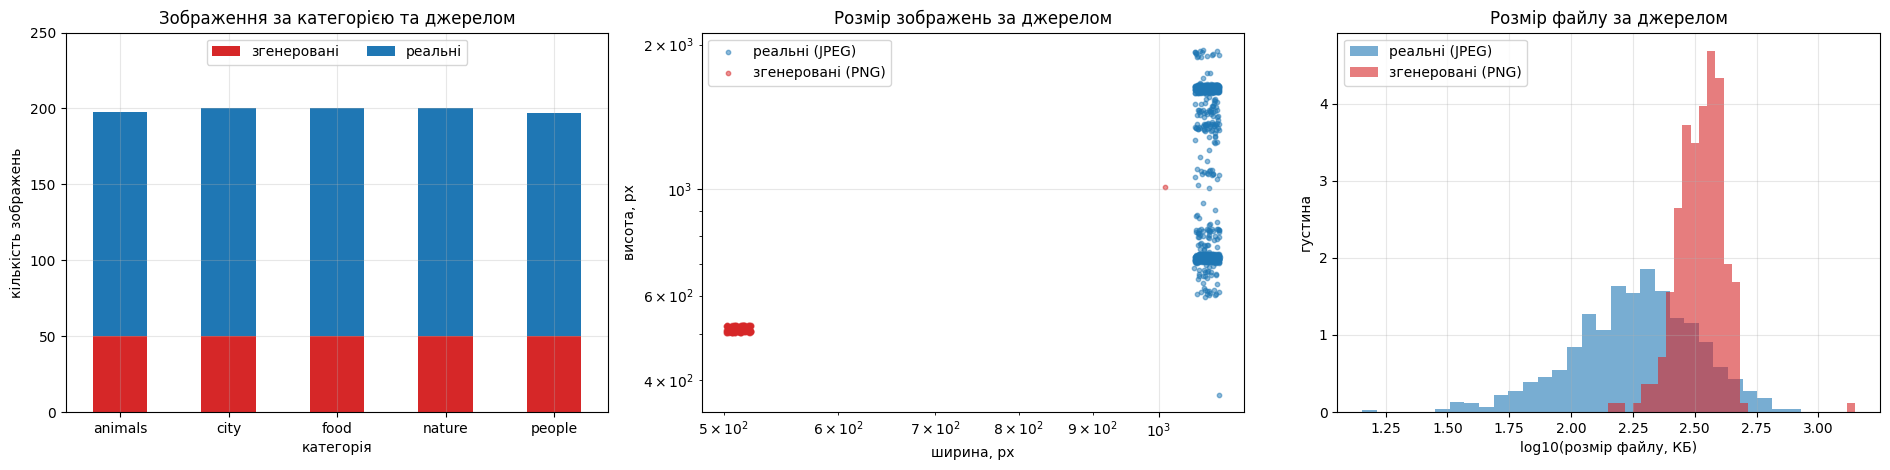

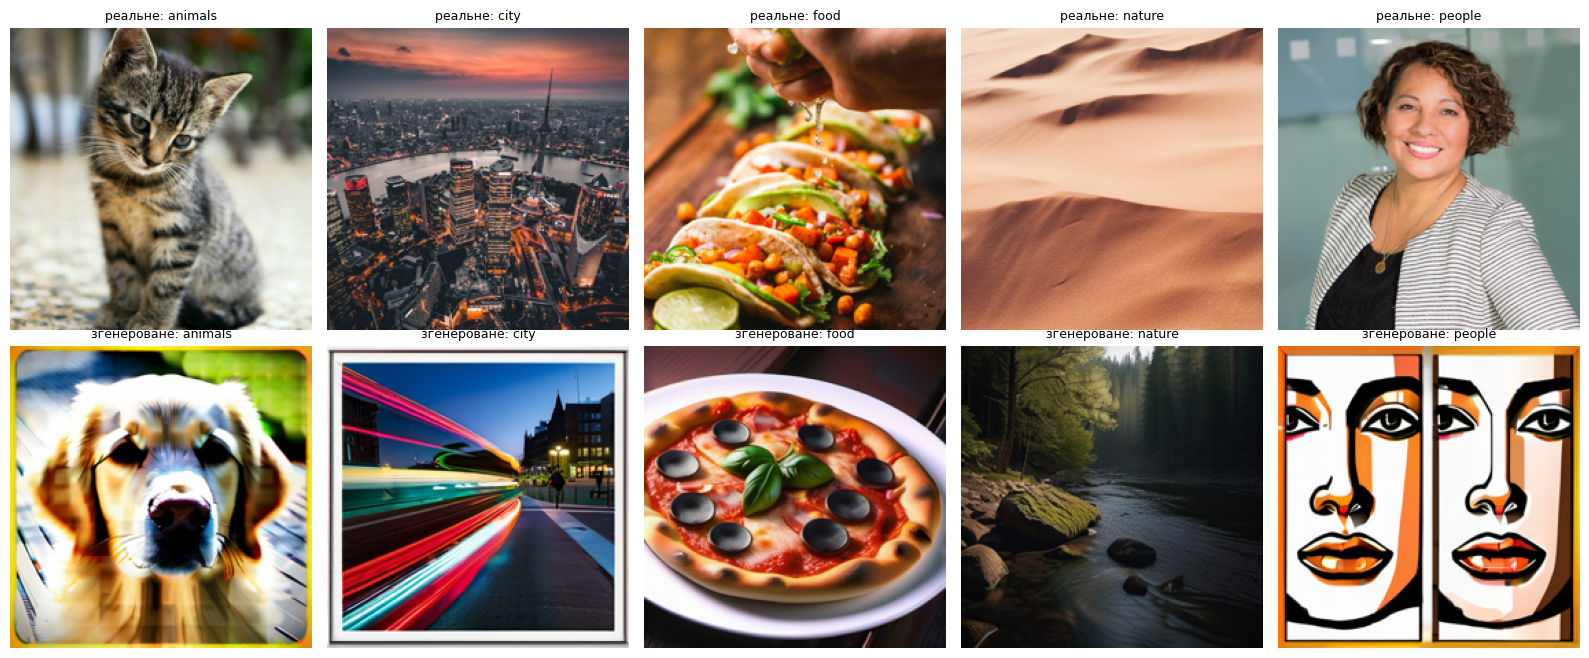

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
pd.crosstab(meta["category"], meta["source"]).plot.bar(ax=ax[0], stacked=True, color=["tab:red", "tab:blue"], rot=0)
ax[0].set_ylabel("кількість зображень"); ax[0].set_xlabel("категорія"); ax[0].set_title("Зображення за категорією та джерелом"); ax[0].set_ylim(0, 250); ax[0].legend(["згенеровані", "реальні"], loc="upper center", ncol=2)

rng = np.random.default_rng(0)
for src, color, lab in [("real", "tab:blue", "реальні (JPEG)"), ("ai", "tab:red", "згенеровані (PNG)")]:       # невеликий шум, щоб точки з однаковим розміром не зливались
    m = meta["source"] == src
    ax[1].scatter(meta.loc[m, "width"] * rng.uniform(0.98, 1.02, m.sum()), meta.loc[m, "height"] * rng.uniform(0.98, 1.02, m.sum()), s=10, alpha=0.5, color=color, label=lab)
    ax[2].hist(np.log10(meta.loc[m, "bytes"] / 1024), bins=30, alpha=0.6, color=color, label=lab, density=True)
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("ширина, px"); ax[1].set_ylabel("висота, px"); ax[1].set_title("Розмір зображень за джерелом"); ax[1].legend()
ax[2].set_xlabel("log10(розмір файлу, КБ)"); ax[2].set_ylabel("густина"); ax[2].set_title("Розмір файлу за джерелом"); ax[2].legend()
plt.tight_layout(); plt.show()

# приклади: по одному зображенню кожної категорії для реальних (верхній ряд) та згенерованих (нижній ряд)
cats = sorted(meta["category"].unique())
fig, ax = plt.subplots(2, len(cats), figsize=(3.2 * len(cats), 6.6))
for i, (src, title) in enumerate([("real", "реальне"), ("ai", "згенероване")]):
    for j, c in enumerate(cats):
        p = rng.choice(meta.loc[(meta["source"] == src) & (meta["category"] == c), "path"])
        ax[i, j].imshow(center_square(Image.open(p).convert("RGB")).resize((220, 220))); ax[i, j].axis("off"); ax[i, j].set_title(f"{title}: {c}", fontsize=9)
plt.tight_layout(); plt.show()

**Висновок.** Набір містить 995 зображень: 745 реальних (JPEG, медіана 1 080×827 px) і 250 згенерованих (усі PNG 512×512). Класи нерівні (25% згенерованих), тому модель, що завжди відповідає «реальне», має accuracy 0.749. Категорій п'ять, у кожній по 50 згенерованих і 147–150 реальних зображень, тож категорії збалансовані щодо джерела. Точних дублікатів немає. Формат і розмір у пікселях повністю збігаються з джерелом, а вага файлу теж різна (медіана 341 КБ у PNG проти 188 КБ у JPEG), тобто класи відрізняються не лише змістом; як це впливає на результат, перевіряємо в п. 6.6.

## 3. Підготовка даних: вирівнювання зображень, ознаки, поділ на вибірки
Етапи:
1. **Точні дублікати.** Видаляємо зайві копії файлів, а групи з однаковим вмістом, але різними мітками, — повністю.
2. **Вирівнювання зображень.** Реальні фото та згенеровані зображення відрізняються форматом (JPEG / PNG), розміром (≈ 1 080 / 512 px) і пропорціями, тому класифікатор може вгадувати клас за цими технічними ознаками (п. 6.6). Щоб це послабити, кожне зображення обрізаємо до центрального квадрата, зменшуємо до 256×256, перекодовуємо в JPEG (якість 90) і стискаємо до 224×224: усі зображення мають однаковий формат, розмір і пропорції. Вплив цього кроку перевіряємо в п. 6.6.
3. **Ознаки зображень.** LSH працює з векторами, тому кожне зображення перетворюємо на вектор із 2048 чисел за допомогою ResNet-50 (попередньо навчена на ImageNet; беремо вихід передостаннього шару) і далі працюємо з цими векторами.
4. **Майже дублікати.** Зображення, що відрізняються лише обрізанням чи яскравістю, мають косинусну схожість векторів, близьку до 1. Перевіряємо, чи є такі пари (> 0.95); у п. 6.7 і 7 додаємо штучні копії.
5. **Поділ:** 75% навчальна та 25% тестова вибірка зі збереженням частки джерела й категорії; групи майже дублікатів не розриваємо. Тестова вибірка використовується лише для фінальної оцінки. Поділ виконує власна стратифікована групова схема `GroupStratifiedKFold`: її результат залежить лише від `random_state` і не змінюється між версіями бібліотек (готовий `StratifiedGroupKFold` у різних версіях sklearn ділить по-різному, тож результати в різних середовищах не збігалися б).

In [5]:
# 1) точні дублікати
n_conf = meta.groupby("md5")["source"].transform("nunique") > 1
meta_all = meta[~n_conf].drop_duplicates("md5").reset_index(drop=True)
print(f"Було {len(meta)}; видалено {int(n_conf.sum())} файлів із суперечливими мітками та {len(meta) - int(n_conf.sum()) - len(meta_all)} зайвих копій; лишилось {len(meta_all)}")

# 2а) вирівнювання: центральний квадрат → 256×256 → JPEG (якість 90) → 224×224 (RGB, uint8)
def equalize(im):
    im = center_square(im.convert("RGB")).resize((256, 256), Image.BILINEAR)
    buf = io.BytesIO()
    im.save(buf, "JPEG", quality=90)
    return np.asarray(Image.open(io.BytesIO(buf.getvalue())).convert("RGB").resize((224, 224), Image.BILINEAR))

IMG_ALL = np.stack([equalize(Image.open(p)) for p in meta_all["path"]])
print("Масив зображень:", IMG_ALL.shape, IMG_ALL.dtype)

Було 995; видалено 0 файлів із суперечливими мітками та 0 зайвих копій; лишилось 995
Масив зображень: (995, 224, 224, 3) uint8


In [6]:
# 2б) вектори ознак: ResNet-50 (ONNX, ImageNet), вихід передостаннього шару = 2048 чисел
MODEL_FILE = "resnet50-v2-7.onnx"
MODEL_URL = "https://media.githubusercontent.com/media/onnx/models/main/validated/vision/classification/resnet/model/resnet50-v2-7.onnx"
EMB_LAYER = "resnetv24_flatten0_reshape0"
_session = {}

def get_embeddings(images, names, emb_file):
    if os.path.exists(emb_file):                     # кеш, щоб не рахувати повторно
        z = np.load(emb_file, allow_pickle=True)
        if list(z["names"]) == list(names):
            return z["E"]
    if "s" not in _session:
        try:
            import onnx, onnxruntime as ort
        except ImportError:
            import subprocess, sys
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "onnx", "onnxruntime"])
            import onnx, onnxruntime as ort
        if not os.path.exists(MODEL_FILE):
            try:
                urllib.request.urlretrieve(MODEL_URL, MODEL_FILE)
            except Exception as e:
                print("Не вдалося завантажити модель:", e)
                from google.colab import files
                print(f"Завантажте файл {MODEL_FILE} вручну:")
                os.rename(next(iter(files.upload())), MODEL_FILE)
        model = onnx.load(MODEL_FILE)
        model.graph.output.extend([onnx.helper.make_tensor_value_info(EMB_LAYER, onnx.TensorProto.FLOAT, [None, 2048])])  # додаємо потрібний шар у виходи
        _session["s"] = ort.InferenceSession(model.SerializeToString(), providers=["CPUExecutionProvider"])
    mean, std = np.array([0.485, 0.456, 0.406], np.float32), np.array([0.229, 0.224, 0.225], np.float32)
    out = []
    for s in range(0, len(images), 32):
        x = ((images[s:s + 32].astype(np.float32) / 255 - mean) / std).transpose(0, 3, 1, 2)   # нормалізація ImageNet, NCHW
        out.append(_session["s"].run([EMB_LAYER], {"data": x})[0])
    E = np.concatenate(out)
    np.savez_compressed(emb_file, E=E, names=np.array(names))
    return E

t0 = time.perf_counter()
E_ALL = get_embeddings(IMG_ALL, meta_all["path"].tolist(), "embeddings_resnet50_aivsreal.npz")
print("Вектори ознак:", E_ALL.shape, f"| час: {time.perf_counter() - t0:.0f} с")

Вектори ознак: (995, 2048) | час: 118 с


In [7]:
# 3) майже дублікати: пари з косинусною схожістю > 0.95 (точний перебір усіх пар)
NEAR_DUP = 0.95
En = E_ALL / np.linalg.norm(E_ALL, axis=1, keepdims=True)
S = En @ En.T
np.fill_diagonal(S, 0)
pairs_exact = np.argwhere(np.triu(S > NEAR_DUP))
n_comp, groups = connected_components(csr_matrix(S > NEAR_DUP), directed=False)      # група — зв'язна компонента пар майже дублікатів
print(f"Пар майже дублікатів (схожість > {NEAR_DUP}): {len(pairs_exact)}; найбільша схожість двох різних зображень: {S.max():.3f}; пар зі схожістю > 0.9: {int(np.triu(S > 0.9).sum())}")
print("Квантилі найбільшої схожості зображення з будь-яким іншим (0, 50, 90, 99, 100%):", np.quantile(S.max(axis=1), [0, 0.5, 0.9, 0.99, 1]).round(3))

meta2, IMG, E = meta_all, IMG_ALL, E_ALL
CLASSES = ["real", "ai"]
LABELS = ["реальне", "згенероване"]
y = (meta2["source"] == "ai").astype(int).to_numpy()                                  # основна мітка: 0 — реальне, 1 — згенероване
CATS = sorted(meta2["category"].unique())
y_cat = meta2["category"].map({c: i for i, c in enumerate(CATS)}).to_numpy()          # додаткова мітка: категорія сцени
print("Після очищення:", len(E), "зображень;", dict(zip(LABELS, np.bincount(y))), "| категорії:", dict(zip(CATS, np.bincount(y_cat))))

Пар майже дублікатів (схожість > 0.95): 0; найбільша схожість двох різних зображень: 0.949; пар зі схожістю > 0.9: 50
Квантилі найбільшої схожості зображення з будь-яким іншим (0, 50, 90, 99, 100%): [0.654 0.83  0.891 0.923 0.949]
Після очищення: 995 зображень; {'реальне': np.int64(745), 'згенероване': np.int64(250)} | категорії: {'animals': np.int64(198), 'city': np.int64(200), 'food': np.int64(200), 'nature': np.int64(200), 'people': np.int64(197)}


In [8]:
class GroupStratifiedKFold:
    """k-кратний поділ зі збереженням частки класів і без розриву груп. Залежить лише від random_state (не від версії sklearn)."""
    def __init__(self, n_splits, random_state=0, use_groups=True):
        self.n_splits, self.random_state, self.use_groups = n_splits, random_state, use_groups

    def split(self, X, y, groups=None):
        y = np.asarray(y)
        groups = np.arange(len(y)) if (groups is None or not self.use_groups) else np.asarray(groups)
        _, yi = np.unique(y, return_inverse=True)
        _, gi = np.unique(groups, return_inverse=True)
        G = np.zeros((gi.max() + 1, yi.max() + 1))
        np.add.at(G, (gi, yi), 1)                                           # склад кожної групи за класами
        rng = np.random.default_rng(self.random_state)
        order = np.lexsort((rng.random(len(G)), -G.sum(axis=1)))           # спершу великі групи, далі випадковий порядок
        target, cnt, fold_of = G.sum(axis=0) / self.n_splits, np.zeros((self.n_splits, G.shape[1])), np.empty(len(G), int)
        for g in order:                                                     # група йде в ту частину, якій найбільше бракує її класів
            f = int(np.argmin((((cnt + G[g] - target) ** 2) - ((cnt - target) ** 2)).sum(axis=1) + 1e-6 * rng.random(self.n_splits)))
            cnt[f] += G[g]; fold_of[g] = f
        fold = fold_of[gi]
        for f in range(self.n_splits):
            yield np.where(fold != f)[0], np.where(fold == f)[0]

# 4) поділ на навчальну (75%) та тестову (25%) вибірки зі збереженням частки джерела й категорії
strata = (meta2["source"] + "_" + meta2["category"]).to_numpy()
train_idx, test_idx = next(GroupStratifiedKFold(4, RANDOM_STATE).split(E, strata, groups))
XT, yT, gT, cT = E[train_idx], y[train_idx], groups[train_idx], y_cat[train_idx]     # навчальна вибірка (для крос-валідації)
XE, yE, cE = E[test_idx], y[test_idx], y_cat[test_idx]                                # тестова вибірка (лише для фінальної оцінки)
CV = GroupStratifiedKFold(5, RANDOM_STATE)                                          # групова 5-кратна крос-валідація
print(f"Навчальна вибірка: {len(XT)}, тестова: {len(XE)}; спільних груп майже дублікатів: {len(set(gT) & set(groups[test_idx]))}")
print("Згенерованих у навчальній / тестовій: {:.3f} / {:.3f}".format(yT.mean(), yE.mean()))
print("Базовий рівень на тесті (завжди найчастіший клас): реальне/згенероване {:.3f}, категорія {:.3f}".format(np.bincount(yE).max() / len(yE), np.bincount(cE).max() / len(cE)))

Навчальна вибірка: 745, тестова: 250; спільних груп майже дублікатів: 0
Згенерованих у навчальній / тестовій: 0.250 / 0.256
Базовий рівень на тесті (завжди найчастіший клас): реальне/згенероване 0.744, категорія 0.204


**Висновок.** Очищення нічого не видалило: усі 995 файлів унікальні, суперечливих міток немає. Для кожного зображення отримано вектор ResNet-50 розмірності 2048. Найбільша косинусна схожість двох різних зображень — 0.949, пар зі схожістю > 0.95 немає (понад 0.9 — лише 50 пар), тобто природних майже дублікатів у наборі немає, і кожна група для поділу складається з одного зображення. Тому в п. 6.7 вплив витоку показуємо на штучних копіях. Навчальна вибірка — 745 зображень, тестова — 250 (частка згенерованих 0.250 та 0.256); базовий рівень на тесті 0.744 для задачі «реальне/згенероване» та 0.204 для категорії. Поділ виконує власний клас `GroupStratifiedKFold`, тому він однаковий у будь-якому середовищі. Тест невеликий: одне зображення дає 0.4 в.п. accuracy, тож різницю менше ≈ 1 в.п. не слід вважати суттєвою.

## 4. Реалізація алгоритму LSH
Використовуємо LSH для косинусної відстані на основі **випадкових гіперплощин** (SimHash), як описано в методичці: кожне зображення (вектор $x$) проєктується на $B$ випадкових векторів $r_i$, а біт сигнатури дорівнює знаку проєкції

$$h_i(x)=\begin{cases}1,& r_i\cdot x>0\\0,& r_i\cdot x\le 0\end{cases}$$

Імовірність того, що біти двох векторів збігаються, залежить лише від кута $\theta$ між ними: $P[h_i(x)=h_i(y)]=1-\theta/\pi$. Тому схожі вектори мають схожі сигнатури, а різниця між сигнатурами (відстань Хеммінга) приблизно пропорційна кутові. Реалізовано два способи пошуку:
- **Пошук за відстанню Хеммінга** (бінарний LSH): порівнюємо $B$-бітні сигнатури побітовою операцією XOR; за бажанням для $M$ найближчих кандидатів додатково точно перераховуємо косинусну схожість.
- **Бакети**: $L$ незалежних хеш-таблиць, у кожній ключ — $b$ біт сигнатури. Кандидати на схожість — об'єкти, що потрапили в той самий бакет хоч в одній таблиці; їх ранжуємо точною косинусною схожістю. Чим більше $b$, тим менше кандидатів; чим більше $L$, тим вища повнота. Якщо жодного кандидата не знайдено, запит обробляється пошуком за Хеммінгом по об'єднаній сигнатурі всіх таблиць (запасний варіант).

Приклад із методички хешує вектор цілими значеннями проєкцій за модулем кількості кошиків, що не зберігає косинусну відстань, тому тут реалізовано варіант із бітовими сигнатурами, описаний у тексті методички.

In [9]:
class LSH:
    """LSH для косинусної відстані (випадкові гіперплощини): бітові сигнатури + хеш-таблиці (бакети)."""
    POPCOUNT = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)   # таблиця кількості одиничних бітів у байті

    def __init__(self, n_bits=64, n_tables=1, seed=0):
        self.n_bits, self.n_tables, self.seed = n_bits, n_tables, seed

    def fit(self, X):
        rng = np.random.default_rng(self.seed)
        self.planes_ = rng.standard_normal((X.shape[1], self.n_bits * self.n_tables)).astype(np.float32)   # B = n_bits·n_tables гіперплощин
        bits = (X @ self.planes_) > 0                                                                       # біти сигнатур
        self.signatures_ = np.packbits(bits, axis=1)                                                        # 8 бітів в одному байті
        weights = 1 << np.arange(self.n_bits, dtype=np.int64)
        self.keys_ = np.stack([bits[:, t * self.n_bits:(t + 1) * self.n_bits].astype(np.int64) @ weights    # ключ бакета для кожної таблиці
                               for t in range(self.n_tables)], axis=1)
        self.tables_ = []
        for t in range(self.n_tables):
            order = np.argsort(self.keys_[:, t], kind="stable")
            self.tables_.append((self.keys_[order, t], order))                                              # відсортовані ключі + індекси об'єктів
        return self

    def hamming(self, Q):
        """Відстані Хеммінга між сигнатурами запитів Q та всіма збереженими об'єктами (побітове XOR + підрахунок бітів)."""
        sig = np.packbits((Q @ self.planes_) > 0, axis=1)
        return self.POPCOUNT[np.bitwise_xor(sig[:, None, :], self.signatures_[None, :, :])].sum(axis=-1, dtype=np.int32)

    def candidates(self, q):
        """Індекси об'єктів, що потрапили в той самий бакет, що й запит q, хоча б в одній таблиці."""
        bits = (q @ self.planes_) > 0
        weights = 1 << np.arange(self.n_bits, dtype=np.int64)
        found = []
        for t, (keys, order) in enumerate(self.tables_):
            key = bits[t * self.n_bits:(t + 1) * self.n_bits].astype(np.int64) @ weights
            found.append(order[np.searchsorted(keys, key, "left"):np.searchsorted(keys, key, "right")])
        return np.unique(np.concatenate(found))

Перевіряємо головну властивість LSH: імовірність збігу біта сигнатури для пари векторів має дорівнювати $1-\theta/\pi$, а відстань Хеммінга між $B$-бітними сигнатурами — приблизно $B\,\theta/\pi$. Беремо 3 000 випадкових пар зображень і 1 024-бітну сигнатуру.

Кореляція між часткою збіжних бітів і теоретичним значенням 1 − θ/π: 0.9551
Середнє абсолютне відхилення: 0.0122


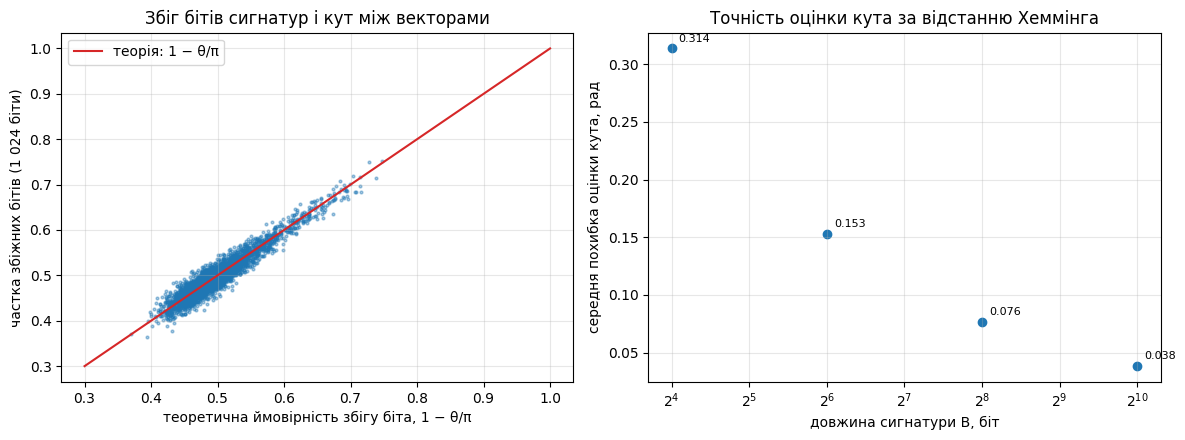

In [10]:
Xc = E - E.mean(axis=0)                                    # центровані вектори (див. 6.1), L2-нормалізація
Xc = Xc / np.linalg.norm(Xc, axis=1, keepdims=True)
rng = np.random.default_rng(RANDOM_STATE)
i, j = rng.integers(0, len(Xc), (2, 3000))
mask = i != j
i, j = i[mask], j[mask]
theta = np.arccos(np.clip((Xc[i] * Xc[j]).sum(axis=1), -1, 1))   # кут між векторами пари

lsh = LSH(n_bits=1024, seed=0).fit(Xc)
bits = np.unpackbits(lsh.signatures_, axis=1)
p_emp = (bits[i] == bits[j]).mean(axis=1)                        # частка збіжних бітів у парі
print("Кореляція між часткою збіжних бітів і теоретичним значенням 1 − θ/π: {:.4f}".format(np.corrcoef(p_emp, 1 - theta / np.pi)[0, 1]))
print("Середнє абсолютне відхилення: {:.4f}".format(np.abs(p_emp - (1 - theta / np.pi)).mean()))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(1 - theta / np.pi, p_emp, s=4, alpha=0.4, color="tab:blue")
ax[0].plot([0.3, 1], [0.3, 1], color="tab:red", label="теорія: 1 − θ/π")
ax[0].set_xlabel("теоретична ймовірність збігу біта, 1 − θ/π"); ax[0].set_ylabel("частка збіжних бітів (1 024 біти)"); ax[0].set_title("Збіг бітів сигнатур і кут між векторами"); ax[0].legend()
for B in [16, 64, 256, 1024]:                                    # розкид оцінки кута залежно від довжини сигнатури
    est = (bits[i, :B] != bits[j, :B]).mean(axis=1) * np.pi
    ax[1].scatter([B], [np.abs(est - theta).mean()], color="tab:blue")
    ax[1].annotate(f"{np.abs(est - theta).mean():.3f}", (B, np.abs(est - theta).mean()), textcoords="offset points", xytext=(5, 5), fontsize=8)
ax[1].set_xscale("log", base=2); ax[1].set_xlabel("довжина сигнатури B, біт"); ax[1].set_ylabel("середня похибка оцінки кута, рад"); ax[1].set_title("Точність оцінки кута за відстанню Хеммінга")
plt.tight_layout(); plt.show()

**Висновок.** Частка збіжних бітів сигнатури з 1 024 бітів добре узгоджується з теоретичною ймовірністю 1 − θ/π: кореляція 0.955, середнє абсолютне відхилення 0.012. Середня похибка оцінки кута за відстанню Хеммінга спадає з довжиною сигнатури: 0.314 рад при 16 бітах, 0.153 при 64, 0.076 при 256 та 0.038 при 1 024, тобто зменшується вдвічі при збільшенні довжини в чотири рази (як 1/√B). Отже, реалізація працює правильно. Теоретична ймовірність збігу біта для більшості пар лежить у вузькому діапазоні (≈ 0.4–0.75): кути між центрованими векторами ознак великі, тому короткі сигнатури розрізняють пари погано.

Допоміжні функції для класифікації та оцінювання. Усі методи нижче (точний kNN, LSH за Хеммінгом, LSH за бакетами) мають однакове правило голосування — клас визначається більшістю серед `k` знайдених сусідів (при рівності голосів перемагає клас ближчого сусіда), тому відмінності в точності зумовлені лише якістю пошуку сусідів. Якість пошуку вимірюємо ще й напряму: **recall@10** — частка 10 справжніх найближчих сусідів (за точним косинусним пошуком), знайдених методом.

In [11]:
K_EVAL = 10

def prepare(Xtr, Xva, mode="center"):
    """Підготовка векторів: без обробки, центрування або z-оцінка за статистиками навчальної частини; потім L2-нормалізація."""
    if mode in ("center", "zscore"):
        mu = Xtr.mean(axis=0)
        Xtr, Xva = Xtr - mu, Xva - mu
    if mode == "zscore":
        sd = Xtr.std(axis=0) + 1e-6
        Xtr, Xva = Xtr / sd, Xva / sd
    nrm = lambda A: (A / np.maximum(np.linalg.norm(A, axis=1, keepdims=True), 1e-12)).astype(np.float32)
    return nrm(Xtr), nrm(Xva)

def vote(ranked, ytr, k):
    """Голосування більшості серед k перших сусідів зі списку ranked (-1 = немає сусіда); при рівності — вигравав ближчий."""
    pred = np.empty(len(ranked), dtype=int)
    for q, r in enumerate(ranked):
        r = r[r >= 0][:k]
        pred[q] = np.bincount(ytr[r], weights=1 + 1e-3 * (k - np.arange(len(r))) / k, minlength=len(CLASSES)).argmax()
    return pred

def exact_rank(Xtr, Xva, n):
    """Точний пошук: n найближчих за косинусною схожістю (вектори вже L2-нормалізовані)."""
    return np.argsort(-(Xva @ Xtr.T), axis=1)[:, :n]

def exact_knn(k=5):
    def method(Xtr, ytr, Xva, seed):
        ranked = exact_rank(Xtr, Xva, max(k, K_EVAL))
        return {"pred": vote(ranked, ytr, k), "ranked": ranked}
    return method

def lsh_hamming(n_bits=64, k=5, M=0):
    """M = 0 — лише відстань Хеммінга; M > 0 — M найближчих за Хеммінгом кандидатів ранжуються точною косинусною схожістю."""
    def method(Xtr, ytr, Xva, seed):
        H = LSH(n_bits, 1, seed).fit(Xtr).hamming(Xva)
        n = max(k, K_EVAL)
        if M == 0:
            ranked = np.argsort(H, axis=1, kind="stable")[:, :n]
        else:
            cand = np.argpartition(H, min(M, H.shape[1]) - 1, axis=1)[:, :M]
            ranked = np.stack([cand[q][np.argsort(-(Xtr[cand[q]] @ Xva[q]))][:n] for q in range(len(Xva))])
        return {"pred": vote(ranked, ytr, k), "ranked": ranked}
    return method

def lsh_buckets(n_bits=8, n_tables=16, k=5):
    def method(Xtr, ytr, Xva, seed):
        lsh = LSH(n_bits, n_tables, seed).fit(Xtr)
        n = max(k, K_EVAL)
        ranked, share, fallback = np.full((len(Xva), n), -1), [], []
        for q in range(len(Xva)):
            cand = lsh.candidates(Xva[q])
            share.append(len(cand) / len(Xtr))
            fallback.append(len(cand) == 0)
            if len(cand) == 0:                                    # жодного кандидата — пошук за Хеммінгом по всій сигнатурі
                found = np.argsort(lsh.hamming(Xva[q:q + 1])[0], kind="stable")[:n]
            else:
                found = cand[np.argsort(-(Xtr[cand] @ Xva[q]))[:n]]
            ranked[q, :len(found)] = found
        return {"pred": vote(ranked, ytr, k), "ranked": ranked, "share": np.mean(share), "fallback": np.mean(fallback)}
    return method

def cv_eval(method, X=None, mode="center", seeds=(0, 1, 2), splitter=None, groups=None, y_=None):
    """Крос-валідація на навчальній вибірці. LSH випадковий, тому повторюємо з різними seed і усереднюємо."""
    X = XT if X is None else X
    y_ = yT if y_ is None else y_
    splitter = splitter or CV
    groups = gT if groups is None else groups
    rows = []
    for seed in seeds:
        pred, rec, share, fb = np.empty(len(y_), dtype=int), [], [], []
        for tr, va in splitter.split(X, y_, groups):
            Xtr, Xva = prepare(X[tr], X[va], mode)
            out = method(Xtr, y_[tr], Xva, seed)
            pred[va] = out["pred"]
            exact10 = exact_rank(Xtr, Xva, K_EVAL)
            rec.append(np.mean([len(set(a[a >= 0][:K_EVAL]) & set(b)) / K_EVAL for a, b in zip(out["ranked"], exact10)]))
            share.append(out.get("share", np.nan)); fb.append(out.get("fallback", np.nan))
        rows.append({"accuracy": accuracy_score(y_, pred), "f1": f1_score(y_, pred, average="macro"), "recall@10": np.mean(rec),
                     "частка кандидатів": np.nanmean(share) if not np.all(np.isnan(share)) else np.nan,
                     "частка запитів без кандидатів": np.nanmean(fb) if not np.all(np.isnan(fb)) else np.nan})
    res = pd.DataFrame(rows)
    return {**res.mean().to_dict(), "± accuracy": res["accuracy"].std() if len(seeds) > 1 else 0.0}

def table(results, cols=("accuracy", "± accuracy", "f1", "recall@10")):
    return pd.DataFrame(results).T[list(cols)]

## 5. Базові моделі
Порівнюємо на тестовій вибірці: точний kNN (`k = 5`, косинусна відстань, перебір усіх навчальних зображень) та LSH із 64-бітною сигнатурою (пошук за Хеммінгом без перерахунку) і з перерахунком 50 кандидатів, а також LSH-бакети (8 біт, 16 таблиць). Вектори центровані за середнім навчальної вибірки й L2-нормалізовані (чому — у п. 6.1). LSH випадковий, тому беремо середнє по 5 різних наборах гіперплощин.

,accuracy,± accuracy,f1
точний kNN (k = 5),0.9120,0.0000,0.8807
"LSH: Хеммінг, 64 біти",0.8672,0.0159,0.8198
"LSH: Хеммінг, 64 біти + перерахунок 50",0.9208,0.0059,0.8909
"LSH: бакети, 8 біт × 16 таблиць",0.9080,0.0166,0.8718


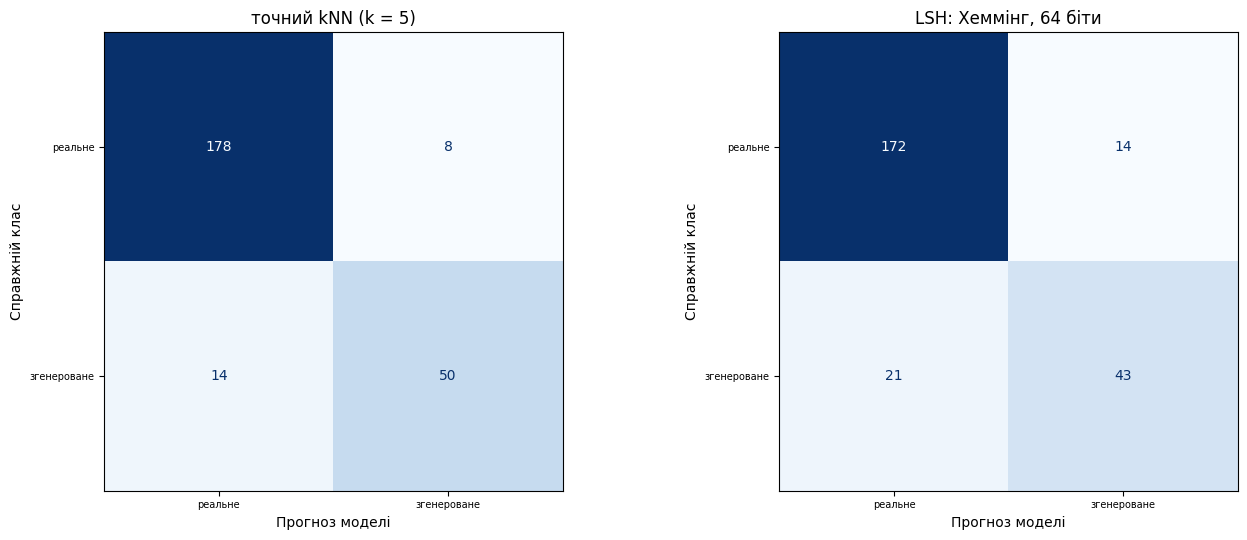

In [12]:
Xtr0, Xte0 = prepare(XT, XE, "center")

def test_eval(method, seeds=(0, 1, 2, 3, 4)):
    accs, f1s, preds = [], [], []
    for s in seeds:
        out = method(Xtr0, yT, Xte0, s)
        accs.append(accuracy_score(yE, out["pred"])); f1s.append(f1_score(yE, out["pred"], average="macro")); preds.append(out["pred"])
    return {"accuracy": np.mean(accs), "± accuracy": np.std(accs), "f1": np.mean(f1s)}, preds[0]

base_methods = {"точний kNN (k = 5)": exact_knn(5), "LSH: Хеммінг, 64 біти": lsh_hamming(64, 5, 0),
                "LSH: Хеммінг, 64 біти + перерахунок 50": lsh_hamming(64, 5, 50), "LSH: бакети, 8 біт × 16 таблиць": lsh_buckets(8, 16, 5)}
base_res, base_pred = {}, {}
for name, m in base_methods.items():
    base_res[name], base_pred[name] = test_eval(m, seeds=(0,) if name.startswith("точний") else (0, 1, 2, 3, 4))
display(pd.DataFrame(base_res).T.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, name in zip(ax, ["точний kNN (k = 5)", "LSH: Хеммінг, 64 біти"]):
    ConfusionMatrixDisplay.from_predictions(yE, base_pred[name], display_labels=LABELS, cmap="Blues", values_format="d", ax=a, colorbar=False)
    a.grid(False); a.set_title(name); a.set_xlabel("Прогноз моделі"); a.set_ylabel("Справжній клас"); a.tick_params(labelsize=7)
plt.tight_layout(); plt.show()

**Висновок.** На тесті точний kNN (k = 5) дає accuracy 0.9120 (F1 0.8807) проти 0.744 у базового рівня. LSH із 64 бітами Хеммінга гірший: 0.8672 ± 0.0159 (F1 0.8198). Якщо 50 найближчих за Хеммінгом кандидатів перерахувати за точною косинусною схожістю, accuracy 0.9208 ± 0.0059, тобто не гірше за точний kNN (різниця 0.9 в.п. — це ≈ 2 зображення з 250); бакетний LSH (8 біт × 16 таблиць) дає 0.9080 ± 0.0166. Розкид між п'ятьма seed у режимі «лише Хеммінг» і в бакетах помітно більший, ніж у режимі з перерахунком. Групова 5-кратна крос-валідація на навчальній вибірці дала для точного kNN 0.9423 (F1 0.9226), тобто приблизно на 3 в.п. вище, ніж на тесті; для 250 зображень стандартна похибка ≈ 1.7 в.п., тому така різниця не виходить за межі шуму.

## 6. Залежність точності й швидкості від параметрів LSH та особливостей даних
Змінюємо по одному фактору, решта — як у базовій моделі. Усі експерименти виконуються 5-кратною групованою крос-валідацією на навчальній вибірці (тестова не використовується); для LSH результат усереднюється по 3 різних наборах випадкових гіперплощин, у таблицях — середнє значення та розкид accuracy (± accuracy; різниці менші за нього не варто вважати значущими). Крім accuracy та macro-F1 (класи незбалансовані) вимірюється recall@10 — наскільки пошук сусідів збігається з точним. Підсумкові значення accuracy збираємо в `FACTORS`.

In [13]:
FACTORS = {}
EXACT = cv_eval(exact_knn(5), seeds=(0,))
print("Точний kNN (k = 5), груповані 5-кратна CV: accuracy = {:.4f}, macro-F1 = {:.4f}".format(EXACT["accuracy"], EXACT["f1"]))

def bar_acc(series, title, figsize=(8, 4)):
    ax = series.sort_values().plot.barh(figsize=figsize, color="tab:blue")
    ax.axvline(EXACT["accuracy"], color="tab:red", ls="--", label="точний kNN")
    ax.set_xlabel("accuracy, крос-валідація"); ax.set_title(title); ax.set_xlim(0, 1)
    ax.bar_label(ax.containers[0], fmt="%.3f", padding=3); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

Точний kNN (k = 5), груповані 5-кратна CV: accuracy = 0.9423, macro-F1 = 0.9226


### 6.1. Підготовка векторів перед хешуванням
Гіперплощини LSH проходять через початок координат. Вектори з ResNet після функції ReLU невід'ємні й зосереджені в одній області простору, тому всі кути між ними малі, а випадкові гіперплощини погано їх розділяють. Порівнюємо вектори без обробки, центровані (віднімання середнього навчальної вибірки) та стандартизовані (z-оцінка); після кожного варіанта — L2-нормалізація. Перевіряємо для точного kNN та LSH (Хеммінг, 64 біти).

In [14]:
MODES = {"без обробки": "raw", "центрування": "center", "z-оцінка": "zscore"}
res_prep = {}
for name, mode in MODES.items():
    res_prep[f"kNN, {name}"] = cv_eval(exact_knn(5), mode=mode, seeds=(0,))
    res_prep[f"LSH 64 біти, {name}"] = cv_eval(lsh_hamming(64, 5, 0), mode=mode)
FACTORS["Підготовка векторів (LSH 64 біти)"] = pd.Series({n: res_prep[f"LSH 64 біти, {n}"]["accuracy"] for n in MODES})
display(table(res_prep).round(4))

,accuracy,± accuracy,f1,recall@10
"kNN, без обробки",0.9275,0.0000,0.9053,1.0000
"LSH 64 біти, без обробки",0.7745,0.0344,0.7223,0.2526
"kNN, центрування",0.9423,0.0000,0.9226,1.0000
"LSH 64 біти, центрування",0.8698,0.0155,0.8249,0.3390
"kNN, z-оцінка",0.9409,0.0000,0.9203,1.0000
"LSH 64 біти, z-оцінка",0.8510,0.0040,0.7985,0.3227


**Висновок.** Центрування векторів помітно допомагає LSH: accuracy зростає з 0.7745 до 0.8698, а recall@10 — з 0.253 до 0.339 (+9.5 в.п. за accuracy); для точного kNN приріст менший (0.9275 → 0.9423, +1.5 в.п.). Імовірна причина: ознаки ResNet після ReLU невід'ємні й мають велику спільну складову, тому вектори лежать у вузькому конусі, а гіперплощини через початок координат майже не розділяють точки; центрування переносить початок у центр даних. Стандартизація (z-оцінка) для kNN дає майже те саме (0.9409), а для LSH гірше за центрування (0.8510), тому далі використовуємо центрування з нормуванням довжини.

### 6.2. Довжина сигнатури (кількість бітів)
Чим довша сигнатура, тим точніше відстань Хеммінга оцінює кут між векторами, але тим більше пам'яті та операцій вона потребує. Порівнюємо пошук лише за відстанню Хеммінга та пошук із перерахунком 50 найближчих кандидатів точною косинусною схожістю.

лише Хеммінг                              Хеммінг + перерахунок 50  \
         accuracy ± accuracy      f1 recall@10                 accuracy   
біт                                                                       
8          0.5682     0.0225  0.5478    0.0796                   0.8761   
16         0.7145     0.0473  0.6528    0.1323                   0.9069   
32         0.7893     0.0117  0.7217    0.2280                   0.9163   
64         0.8698     0.0155  0.8249    0.3390                   0.9360   
128        0.9074     0.0182  0.8754    0.4817                   0.9400   
256        0.9289     0.0040  0.9042    0.6145                   0.9423   
512        0.9284     0.0047  0.9044    0.7139                   0.9418   
1024       0.9378     0.0056  0.9170    0.7873                   0.9423   

                                   
     ± accuracy      f1 recall@10  
біт                                
8        0.0054  0.8288    0.2810  
16       0.0043  0.8715    0.3851  
32       0.0076  0.8870    0.5607  
64       0.0056  0.9130    0.7172  
128      0.0047  0.9197    0.8633  
256      0.0023  0.9224    0.9511  
512      0.0008  0.9219    0.9867  
1024     0.0000  0.9226    0.9978

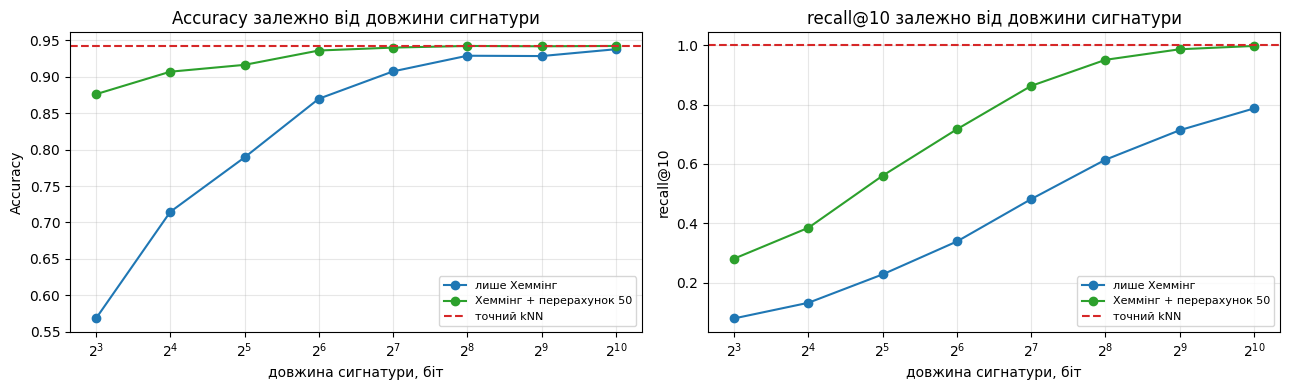

In [15]:
BITS = [8, 16, 32, 64, 128, 256, 512, 1024]
res_h, res_hr = {b: cv_eval(lsh_hamming(b, 5, 0)) for b in BITS}, {b: cv_eval(lsh_hamming(b, 5, 50)) for b in BITS}
FACTORS["Довжина сигнатури (Хеммінг)"] = pd.Series({b: r["accuracy"] for b, r in res_h.items()})
tbl = pd.concat({"лише Хеммінг": table(res_h), "Хеммінг + перерахунок 50": table(res_hr)}, axis=1).rename_axis("біт")
display(tbl.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for res, label, color in [(res_h, "лише Хеммінг", "tab:blue"), (res_hr, "Хеммінг + перерахунок 50", "tab:green")]:
    ax[0].plot(BITS, [r["accuracy"] for r in res.values()], marker="o", label=label, color=color)
    ax[1].plot(BITS, [r["recall@10"] for r in res.values()], marker="o", label=label, color=color)
ax[0].axhline(EXACT["accuracy"], color="tab:red", ls="--", label="точний kNN")
ax[1].axhline(1, color="tab:red", ls="--", label="точний kNN")
for a, t in zip(ax, ["Accuracy", "recall@10"]):
    a.set_xscale("log", base=2); a.set_xlabel("довжина сигнатури, біт"); a.set_ylabel(t); a.set_title(t + " залежно від довжини сигнатури"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Висновок.** Для режиму «лише Хеммінг» accuracy швидко зростає з довжиною сигнатури: 0.568 (8 біт), 0.715 (16), 0.789 (32), 0.870 (64), 0.907 (128), 0.929 (256), 0.928 (512), 0.938 (1 024), що наближається до точного kNN (0.942). Розкид між seed спадає з ± 0.023 при 8 бітах до ± 0.004 при 256 (найбільший при 16 бітах, ± 0.047). Recall@10 при цьому лишається невисоким (0.615 при 256 бітах, 0.787 при 1 024). З перерахунком 50 кандидатів accuracy вища на всіх довжинах і вже від 32 біт (0.916) відрізняється від точної менш ніж на 3 в.п.: 0.876 при 8 бітах, 0.936 при 64, 0.942 при 256 (recall@10 0.281, 0.717 та 0.951 відповідно). Отже, для класифікації не потрібні всі точні сусіди: достатньо, щоб серед кандидатів були зображення того ж класу. Практичний вибір — 128–256 біт, довші сигнатури нічого не додають.

### 6.3. Бакети: біти в ключі (b) та кількість хеш-таблиць (L)
У бакетному режимі кандидатами стають лише об'єкти з тим самим ключем хоча б в одній із L таблиць. Збільшення `b` робить бакети меншими (менше кандидатів, але нижча повнота), збільшення `L` підвищує повноту ціною більшої кількості кандидатів. Для кожної пари (b, L) дивимось на accuracy, частку навчальних об'єктів, що стали кандидатами (чим менша, тим швидше пошук), частку запитів без жодного кандидата та recall@10.

Медіанний кут до 10 найближчих сусідів: 61.5° (ймовірність збігу одного біта p = 0.66)


accuracy  recall@10  теор. recall@10  \
b (біт у ключі) L (таблиць)                                         
6               4               0.894      0.287            0.308   
                8               0.916      0.499            0.507   
                16              0.931      0.717            0.734   
                32              0.938      0.899            0.909   
8               4               0.830      0.146            0.156   
                8               0.866      0.259            0.279   
                16              0.914      0.427            0.461   
                32              0.931      0.651            0.675   
10              4               0.789      0.089            0.078   
                8               0.828      0.124            0.146   
                16              0.863      0.243            0.259   
                32              0.906      0.411            0.425   
12              4               0.776      0.120            0.039   
                8               0.789      0.111            0.075   
                16              0.825      0.134            0.139   
                32              0.864      0.235            0.244   

                             частка кандидатів  частка запитів без кандидатів  
b (біт у ключі) L (таблиць)                                                    
6               4                        0.070                          0.000  
                8                        0.134                          0.000  
                16                       0.241                          0.000  
                32                       0.406                          0.000  
8               4                        0.022                          0.000  
                8                        0.043                          0.000  
                16                       0.077                          0.000  
                32                       0.143                          0.000  
10              4                        0.007                          0.049  
                8                        0.013                          0.003  
                16                       0.026                          0.000  
                32                       0.050                          0.000  
12              4                        0.002                          0.308  
                8                        0.004                          0.123  
                16                       0.009                          0.022  
                32                       0.018                          0.001

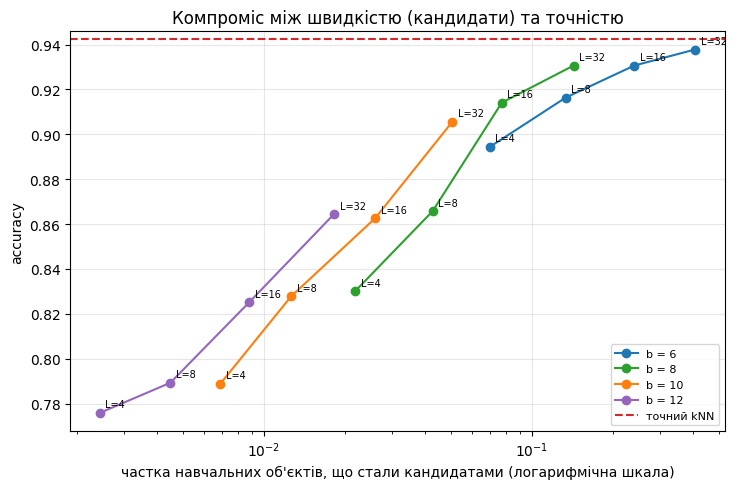

In [16]:
BS, LS = [6, 8, 10, 12], [4, 8, 16, 32]
res_b = {(b, L): cv_eval(lsh_buckets(b, L, 5)) for b in BS for L in LS}
tb = pd.DataFrame(res_b).T.rename_axis(["b (біт у ключі)", "L (таблиць)"])

# теорія: сусід потрапляє в той самий бакет хоча б в одній таблиці з імовірністю 1 − (1 − p^b)^L, p = 1 − θ/π
Xc_, _ = prepare(XT, XT[:1], "center")
sim_ = Xc_ @ Xc_.T
np.fill_diagonal(sim_, -1)
theta_nn = np.arccos(np.clip(np.sort(sim_, axis=1)[:, -K_EVAL:], -1, 1))      # кути до 10 найближчих сусідів кожного зображення
print("Медіанний кут до 10 найближчих сусідів: {:.1f}° (ймовірність збігу одного біта p = {:.2f})".format(np.degrees(np.median(theta_nn)), 1 - np.median(theta_nn) / np.pi))
tb["теор. recall@10"] = [np.mean(1 - (1 - (1 - theta_nn / np.pi) ** b) ** L) for b, L in tb.index]
FACTORS["Бакети (b, L)"] = pd.Series({f"b={b}, L={L}": r["accuracy"] for (b, L), r in res_b.items()})
display(tb[["accuracy", "recall@10", "теор. recall@10", "частка кандидатів", "частка запитів без кандидатів"]].round(3))

fig, ax = plt.subplots(figsize=(7.5, 5))
for b, color in zip(BS, ["tab:blue", "tab:green", "tab:orange", "tab:purple"]):
    sub = tb.xs(b, level=0)
    ax.plot(sub["частка кандидатів"], sub["accuracy"], marker="o", color=color, label=f"b = {b}")
    for L, r in sub.iterrows():
        ax.annotate(f"L={L}", (r["частка кандидатів"], r["accuracy"]), textcoords="offset points", xytext=(4, 4), fontsize=7)
ax.axhline(EXACT["accuracy"], color="tab:red", ls="--", label="точний kNN")
ax.set_xscale("log"); ax.set_xlabel("частка навчальних об'єктів, що стали кандидатами (логарифмічна шкала)"); ax.set_ylabel("accuracy")
ax.set_title("Компроміс між швидкістю (кандидати) та точністю"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Висновок.** У бакетному LSH recall@10 та accuracy залежать від довжини ключа b і числа таблиць L, а частка кандидатів — це ціна за них. При b = 6 і L = 32 recall@10 = 0.899, accuracy 0.938, але переглядається 40.6% бази; при b = 8, L = 32 — recall 0.651, accuracy 0.931 та 14.3% кандидатів; при b = 10 — 0.411, 0.906 та 5.0%; при b = 12 — лише 0.235, 0.864 та 1.8%. Теоретична формула 1 − (1 − p^b)^L з p = 0.66 (медіанний кут до 10 найближчих сусідів 61.5°) добре передбачає емпіричний recall (напр., b = 8, L = 16: 0.461 проти 0.427; b = 6, L = 32: 0.909 проти 0.899). Виняток — довгі ключі з малим L (b = 12, L = 4: 0.039 проти 0.120), імовірно, тому що теорія бере один кут для всіх пар, а реальні кути розподілені ширше, і тому що запити без кандидатів обробляє запасний пошук за Хеммінгом. За довгих ключів і малого L чимало запитів не отримують кандидатів (30.8% при b = 12, L = 4), що знижує accuracy до 0.776; тому потрібен запасний варіант пошуку.

### 6.4. Кількість сусідів k
Мале `k` робить класифікацію чутливою до окремих зображень, велике — «розмиває» малі класи. Дивимось, чи залежність від `k` у LSH така сама, як у точного kNN.

,точний kNN,LSH 256 біт (Хеммінг),LSH 256 біт + перерахунок 50
k,,,
1,0.9262,0.9123,0.9271
3,0.9477,0.9280,0.9477
5,0.9423,0.9289,0.9423
7,0.9409,0.9298,0.9423
10,0.9356,0.9342,0.9383
15,0.9302,0.9230,0.9280
25,0.9128,0.9083,0.9141


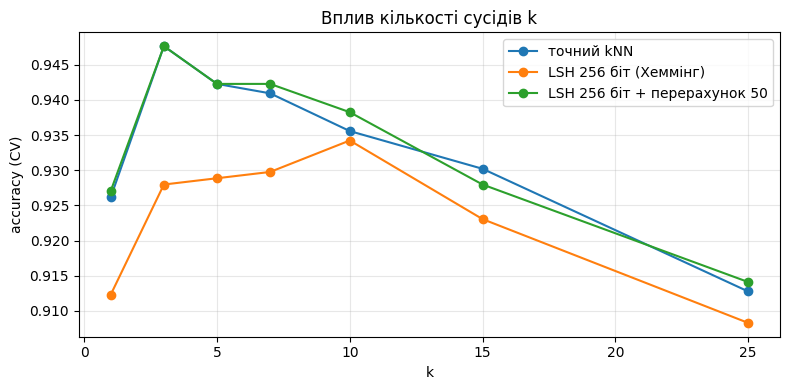

In [17]:
KS = [1, 3, 5, 7, 10, 15, 25]
res_k = {k: {"точний kNN": cv_eval(exact_knn(k), seeds=(0,))["accuracy"],
             "LSH 256 біт (Хеммінг)": cv_eval(lsh_hamming(256, k, 0))["accuracy"],
             "LSH 256 біт + перерахунок 50": cv_eval(lsh_hamming(256, k, 50))["accuracy"]} for k in KS}
res_k = pd.DataFrame(res_k).T.rename_axis("k")
FACTORS["Кількість сусідів k"] = res_k["точний kNN"]
display(res_k.round(4))
ax = res_k.plot(marker="o", figsize=(8, 4)); ax.set_ylabel("accuracy (CV)"); ax.set_title("Вплив кількості сусідів k"); plt.tight_layout(); plt.show()

**Висновок.** Для точного kNN accuracy немонотонна на початку: 0.9262 (k = 1), 0.9477 (3), 0.9423 (5), 0.9409 (7), 0.9356 (10), 0.9302 (15), а при k = 25 падає до 0.9128. Після піку при k = 3 accuracy поступово спадає; різниця між k від 1 до 15 сягає 2.2 в.п., тож на такому розмірі вибірки її важко відрізнити від шуму. Спад при великому k імовірно пов'язаний з тим, що згенерованих лише 25%, і далекі сусіди змішуються з реальними. LSH на 256 біт без перерахунку нижчий за точний kNN на 0.1–2.0 в.п. (0.9342 при k = 10), а з перерахунком 50 збігається з ним у межах 0.3 в.п. (0.9383 при k = 10). Тобто вибір k впливає однаково на точний та наближений пошук.

### 6.5. Представлення зображень
LSH лише хешує вектори, а їхня інформативність залежить від способу перетворення зображення на вектор. Порівнюємо пікселі чорно-білого зображення 32×32, колірну гістограму HSV, ознаки HOG (форма контурів) та вектори ResNet-50. Для кожного — точний kNN та LSH (256 біт; Хеммінг та Хеммінг + перерахунок 50).

In [18]:
def block_mean(a, f):                                 # зменшення зображення усередненням блоків f×f
    h, w = a.shape[:2]
    return a.reshape(h // f, f, w // f, f, *a.shape[2:]).mean(axis=(1, 3))

small = np.stack([np.asarray(Image.fromarray(im).resize((64, 64), Image.BILINEAR)) for im in IMG])      # 64×64 RGB
FEATS = {
    "пікселі (сірі, 32×32)":    np.stack([block_mean(rgb2gray(im), 7).ravel() for im in IMG]),
    "гістограма HSV (8×4×4)":   np.stack([np.histogramdd(rgb2hsv(im).reshape(-1, 3), bins=(8, 4, 4), range=((0, 1),) * 3)[0].ravel() / 4096 for im in small]),
    "HOG (64×64)":              np.stack([hog(rgb2gray(im), orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2)) for im in small]),
    "ResNet-50 (2048)":         E,
}
res_f = {}
for name, F in FEATS.items():
    Ft = F[train_idx]
    res_f[name] = {"розмірність": F.shape[1],
                   "точний kNN": cv_eval(exact_knn(5), X=Ft, seeds=(0,))["accuracy"],
                   "LSH 256 біт (Хеммінг)": cv_eval(lsh_hamming(256, 5, 0), X=Ft)["accuracy"],
                   "LSH 256 біт + перерахунок 50": cv_eval(lsh_hamming(256, 5, 50), X=Ft)["accuracy"]}
res_f = pd.DataFrame(res_f).T
FACTORS["Представлення зображень (kNN)"] = res_f["точний kNN"]
display(res_f.round(4))
print("Базовий рівень (завжди найчастіший клас): {:.3f}".format(np.bincount(yT).max() / len(yT)))

,розмірність,точний kNN,LSH 256 біт (Хеммінг),LSH 256 біт + перерахунок 50
"пікселі (сірі, 32×32)",1024.0,0.7584,0.7606,0.7602
гістограма HSV (8×4×4),128.0,0.7987,0.7928,0.7991
HOG (64×64),1764.0,0.8362,0.7852,0.8224
ResNet-50 (2048),2048.0,0.9423,0.9289,0.9423


Базовий рівень (завжди найчастіший клас): 0.750


**Висновок.** Якість визначається насамперед ознаками. Сірі пікселі 32×32 дають 0.7584 (точний kNN) та 0.7606 (LSH 256 біт) при базовому рівні 0.750, тобто майже нічого; гістограма HSV — 0.7987 / 0.7928; HOG — 0.8362 / 0.7852 (з перерахунком 0.8224); ResNet-50 — 0.9423 / 0.9289 (з перерахунком 0.9423). LSH не покращує слабкі ознаки: він лише наближає kNN у тому ж просторі. На HOG втрата без перерахунку найбільша (5.1 в.п.), імовірно, тому що в такому просторі кути між об'єктами різного класу й одного класу відрізняються слабше, а перерахунок повертає більшість втрати (лишається 1.4 в.п.).

### 6.6. Артефакт датасету: формат і розмір файлів
У п. 2 показано, що всі реальні фото — JPEG ≈ 1 080 px, а всі згенеровані — PNG 512×512. Це **шорткат**: класифікатор може вгадувати джерело файлу, а не розпізнавати зміст, тому точність за міткою «реальне / згенероване» слід читати як «розділення двох джерел», а не як якість виявлення згенерованого контенту. Для самого LSH це не вада: його порівнюють із точним kNN на тих самих векторах. Перевіряємо:
- **(а)** чи можна визначити клас, **не аналізуючи зміст**: за метаданими файлу (ширина, висота, пропорції, розмір у байтах, формат) та за простими статистиками пікселів вирівняних зображень (середнє й розкид кольору, різкість — середнє та дисперсія лапласіана);
- **(б)** чи залежить результат ResNet від обробки: порівнюємо вектори зображень, просто зменшених до 224×224, вирівняних (п. 3) та **контрольних** — зменшених до 96×96 (усереднення по області) і знову збільшених до 224×224; так стираються дрібні сліди формату, JPEG-блоків і різної роздільності, лишається грубий вміст;
- **(в)** чи розрізняється друга мітка — категорія сцени: обидва джерела мають однакові категорії, тому за форматом її не вгадати.

Базовий рівень (завжди «реальне»): 0.750


,accuracy
"метадані файлу (ширина, висота, пропорції, розмір, формат): дерево",1.0000
лише розмір файлу та пропорції: дерево,0.9785
статистики пікселів вирівняних зображень: SVM,0.8953
"ResNet, лише зменшення до 224×224: kNN",0.9450
"ResNet, лише зменшення до 224×224: LSH 256 біт",0.9266
"ResNet, лише зменшення до 224×224: SVM",0.9584
"ResNet, вирівняні зображення: kNN",0.9423
"ResNet, вирівняні зображення: LSH 256 біт",0.9289
"ResNet, вирівняні зображення: SVM",0.9611
"ResNet, контроль 96×96: kNN",0.9409


Категорія сцени (базовий рівень 0.203): метадані файлу → дерево 0.289; ResNet (вирівняні) → kNN 0.933


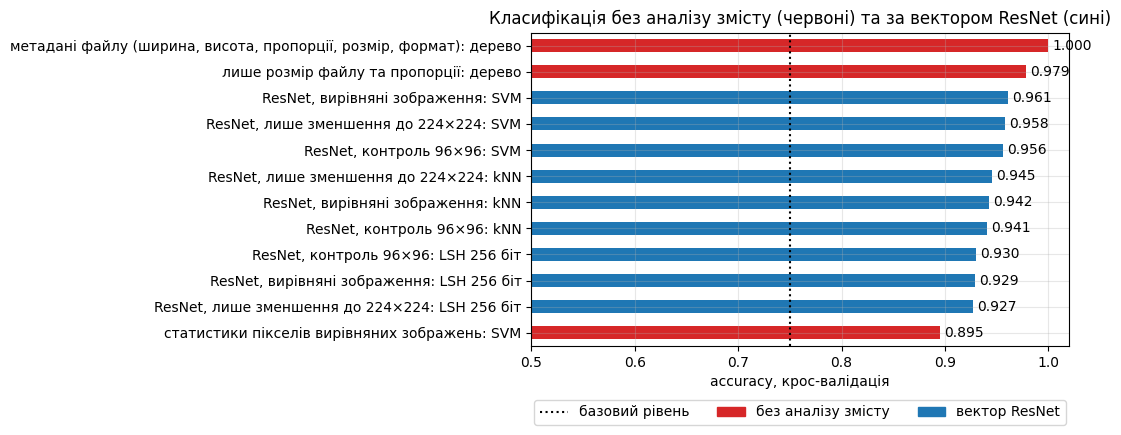

In [19]:
meta_feats = np.c_[meta2["width"], meta2["height"], meta2["aspect"], meta2["bytes"], (meta2["format"] == "PNG")].astype(float)

def lap_stats(a):
    """Різкість: середнє та дисперсія модуля лапласіана сірого зображення."""
    g = a.astype(np.float32).mean(axis=2)
    lap = np.abs(4 * g[1:-1, 1:-1] - g[:-2, 1:-1] - g[2:, 1:-1] - g[1:-1, :-2] - g[1:-1, 2:])
    return [lap.mean(), lap.var()]
pix_feats = np.stack([[*im.reshape(-1, 3).mean(axis=0), *im.reshape(-1, 3).std(axis=0), *lap_stats(im)] for im in IMG])

def cv_sk(make_model, F, target=None):
    """Accuracy групової крос-валідації на навчальній вибірці для моделі sklearn (за замовчуванням ціль — реальне/згенероване)."""
    Ft, t = F[train_idx], (yT if target is None else target)
    return np.mean([accuracy_score(t[va], make_model().fit(Ft[tr], t[tr]).predict(Ft[va])) for tr, va in CV.split(Ft, t, gT)])
tree = lambda: DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
svm_rbf = lambda: make_pipeline(StandardScaler(), SVC(C=10))

# ResNet на зображеннях, просто зменшених до 224×224 (без вирівнювання)
IMG_RAW = np.stack([np.asarray(Image.open(p).convert("RGB").resize((224, 224), Image.BILINEAR)) for p in meta2["path"]])
E_RAW = get_embeddings(IMG_RAW, meta2["path"].tolist(), "embeddings_resnet50_aivsreal_raw.npz")

def lowpass(path, s=96):
    """Контроль: центральний квадрат → s×s (усереднення по області) → 224×224; дрібні сліди формату й стиснення стираються."""
    im = center_square(Image.open(path).convert("RGB")).resize((s, s), Image.BOX)
    return np.asarray(im.resize((224, 224), Image.BILINEAR))
IMG_LOW = np.stack([lowpass(p) for p in meta2["path"]])
E_LOW = get_embeddings(IMG_LOW, meta2["path"].tolist(), "embeddings_resnet50_aivsreal_low96.npz")

res_art = {"метадані файлу (ширина, висота, пропорції, розмір, формат): дерево": {"accuracy": cv_sk(tree, meta_feats)},
           "лише розмір файлу та пропорції: дерево": {"accuracy": cv_sk(tree, meta_feats[:, [2, 3]])},
           "статистики пікселів вирівняних зображень: SVM": {"accuracy": cv_sk(svm_rbf, pix_feats)}}
for name, EE in [("ResNet, лише зменшення до 224×224", E_RAW), ("ResNet, вирівняні зображення", E), ("ResNet, контроль 96×96", E_LOW)]:
    Et = EE[train_idx]
    res_art[name + ": kNN"] = {"accuracy": cv_eval(exact_knn(5), X=Et, seeds=(0,))["accuracy"]}
    res_art[name + ": LSH 256 біт"] = {"accuracy": cv_eval(lsh_hamming(256, 5, 0), X=Et)["accuracy"]}
    res_art[name + ": SVM"] = {"accuracy": cv_sk(svm_rbf, EE)}
res_art = pd.DataFrame(res_art).T
print("Базовий рівень (завжди «реальне»): {:.3f}".format(1 - yT.mean()))
display(res_art.round(4))
FACTORS["Обробка зображень перед ResNet (kNN)"] = pd.Series({"лише зменшення": res_art.loc["ResNet, лише зменшення до 224×224: kNN", "accuracy"], "вирівняні": res_art.loc["ResNet, вирівняні зображення: kNN", "accuracy"],
                                                              "контроль 96×96": res_art.loc["ResNet, контроль 96×96: kNN", "accuracy"]})
print("Категорія сцени (базовий рівень {:.3f}): метадані файлу → дерево {:.3f}; ResNet (вирівняні) → kNN {:.3f}".format(
    np.bincount(cT).max() / len(cT), cv_sk(tree, meta_feats, cT), cv_eval(exact_knn(5), y_=cT, seeds=(0,))["accuracy"]))

ax = res_art["accuracy"].sort_values().plot.barh(figsize=(11, 4.5), color=["tab:red" if ("метадані" in n or "лише розмір" in n or "статистики" in n) else "tab:blue" for n in res_art["accuracy"].sort_values().index])
ax.axvline(1 - yT.mean(), color="black", ls=":"); ax.set_xlim(0.5, 1.02); ax.set_xlabel("accuracy, крос-валідація"); ax.set_title("Класифікація без аналізу змісту (червоні) та за вектором ResNet (сині)")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
ax.legend(handles=[Line2D([], [], color="black", ls=":", label="базовий рівень"), Patch(color="tab:red", label="без аналізу змісту"), Patch(color="tab:blue", label="вектор ResNet")],
          loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3); plt.tight_layout(); plt.show()

Також дивимось, де помиляються моделі: частку правильних відповідей окремо для реальних та згенерованих зображень і для кожної категорії (за результатами крос-валідації на навчальній вибірці).

,реальні,згенеровані,animals,city,food,nature,people
точний kNN (k = 5),0.9642,0.8763,0.9527,0.9799,0.9600,0.9338,0.8844
LSH 64 біти (Хеммінг),0.9302,0.7097,0.8919,0.9128,0.9067,0.8411,0.8231
LSH 256 біт (Хеммінг),0.9535,0.8387,0.9189,0.9664,0.9333,0.9139,0.8912
LSH 256 біт + перерахунок 50,0.9642,0.8656,0.9392,0.9866,0.9533,0.9272,0.8912


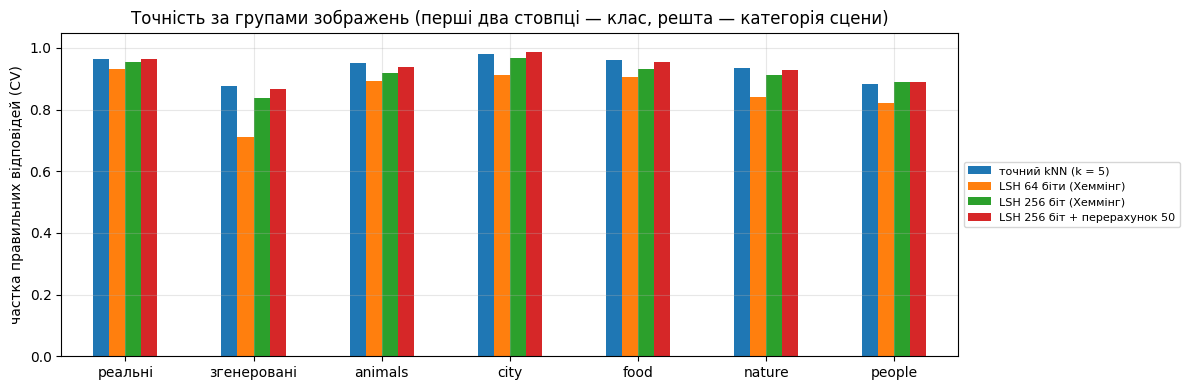

In [20]:
def cv_pred(method, seed=0, mode="center"):
    """Прогнози на всій навчальній вибірці, отримані крос-валідацією."""
    pred = np.empty(len(yT), dtype=int)
    for tr, va in CV.split(XT, yT, gT):
        Xtr, Xva = prepare(XT[tr], XT[va], mode)
        pred[va] = method(Xtr, yT[tr], Xva, seed)["pred"]
    return pred

cat_T = meta2["category"].to_numpy()[train_idx]
subsets = {"реальні": yT == 0, "згенеровані": yT == 1, **{f"{c}": cat_T == c for c in CATS}}
res_sub = {}
for name, m in [("точний kNN (k = 5)", exact_knn(5)), ("LSH 64 біти (Хеммінг)", lsh_hamming(64, 5, 0)),
                ("LSH 256 біт (Хеммінг)", lsh_hamming(256, 5, 0)), ("LSH 256 біт + перерахунок 50", lsh_hamming(256, 5, 50))]:
    p = cv_pred(m)
    res_sub[name] = {k: (p[v] == yT[v]).mean() for k, v in subsets.items()}
res_sub = pd.DataFrame(res_sub).T
display(res_sub.round(4))

ax = res_sub.T.plot.bar(figsize=(12, 4), rot=0)
ax.set_ylabel("частка правильних відповідей (CV)"); ax.set_ylim(0, 1.05); ax.set_title("Точність за групами зображень (перші два стовпці — клас, решта — категорія сцени)")
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5)); plt.tight_layout(); plt.show()

**Висновок.** Тут видно слабке місце набору. Дерево рішень лише за метаданими файлу (ширина, висота, пропорції, розмір, формат) розрізняє класи без жодної помилки (accuracy 1.000), а лише за розміром файлу та пропорціями — 0.9785, при базовому 0.750. Тому точність моделей на ResNet слід читати як «розділення двох джерел файлів», а не як якість виявлення згенерованих зображень. Контролі показують таке. Вирівнювання (квадратне обрізання, 256 px, повторне JPEG-стискання, 224 px) майже не змінює результат: kNN 0.9450 → 0.9423, LSH 256 біт 0.9266 → 0.9289, SVM 0.9584 → 0.9611. Жорсткіший контроль — зображення, зменшені до 96×96 і збільшені назад, коли дрібні сліди формату, JPEG-блоків і різної роздільності стерті, — лишає точність майже такою самою: kNN 0.9409, LSH 0.9298, SVM 0.9557 (розмах для kNN лише 0.4 в.п.). Отже, ResNet не спирається на дрібні технічні сліди. Але це не доводить, що сигнал лише в змісті: прості статистики пікселів вирівняних зображень (колір, розкид, різкість) дають 0.8953, тобто джерела відрізняються й грубими властивостями. Для другої мітки шортката практично немає: метадані дають лише 0.289 для категорії сцени (базовий рівень 0.203), а kNN на векторах ResNet — 0.933, тож вектори справді відображають зміст сцени. Помилки нерівномірні: для точного kNN реальні розпізнано правильно у 96.4% випадків, згенеровані — у 87.6%, за категоріями результат 0.884–0.980 (найгірше people, найкраще city). LSH на 64 бітах погіршує це (згенеровані 71.0%; people 0.823), а 256 біт із перерахунком майже не відрізняються від точного kNN (згенеровані 86.6%).

### 6.7. Штучні копії та витік даних
У цьому датасеті немає природних майже дублікатів (п. 3), але в реальних колекціях вони трапляються (одне зображення, збережене після кадрування чи зміни яскравості). Показуємо, чим це небезпечно, на штучних копіях: беремо 200 випадкових зображень навчальної вибірки й створюємо для кожного копію — випадкове кадрування (92–98% сторони) та зміна яскравості (±10%), після чого копію проводимо через ту саму обробку й ResNet. Копії додаємо до навчальної вибірки. Якщо перевірочну частину формувати випадково (групи не враховуються), оригінал і його копія можуть потрапити в різні частини, і метод «підгляне» відповідь; групова крос-валідація (оригінал і копія разом) цього не допускає.

In [21]:
def augment(im, rng):
    """Штучна копія: випадкове кадрування (92–98% сторони) та зміна яскравості (±10%)."""
    im = im.convert("RGB")
    w, h = im.size
    s = rng.uniform(0.92, 0.98)
    cw, ch = int(w * s), int(h * s)
    l, t = rng.integers(0, w - cw + 1), rng.integers(0, h - ch + 1)
    a = np.asarray(im.crop((l, t, l + cw, t + ch)).resize((w, h), Image.BILINEAR)).astype(np.float32) * rng.uniform(0.9, 1.1)
    return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))

aug_rng = np.random.default_rng(RANDOM_STATE)
copy_src = np.sort(train_idx[np.argsort(aug_rng.random(len(train_idx)))[:200]])                   # оригінали — лише з навчальної вибірки
IMG_COPY = np.stack([equalize(augment(Image.open(meta2.loc[i, "path"]), aug_rng)) for i in copy_src])
E_COPY = get_embeddings(IMG_COPY, [f"copy_{i}" for i in copy_src], "embeddings_resnet50_aivsreal_copies.npz")
Ecn = E_COPY / np.linalg.norm(E_COPY, axis=1, keepdims=True)
cos_copy = (Ecn * En[copy_src]).sum(axis=1)
print("Косинусна схожість копії з оригіналом (квантилі 0, 10, 50, 90, 100%):", np.quantile(cos_copy, [0, 0.1, 0.5, 0.9, 1]).round(3), "| частка > 0.95: {:.3f}".format((cos_copy > NEAR_DUP).mean()))

# навчальна вибірка + копії; оригінал і його копія належать одній групі
X_ext, y_ext, g_ext = np.r_[XT, E_COPY], np.r_[yT, y[copy_src]], np.r_[gT, groups[copy_src]]
naive_cv = GroupStratifiedKFold(5, RANDOM_STATE, use_groups=False)                  # звичайний поділ: групи не враховуються
Xn_ = X_ext / np.linalg.norm(X_ext, axis=1, keepdims=True)
Sim_ = Xn_ @ Xn_.T
np.fill_diagonal(Sim_, 0)

def dup_share(splitter):
    """Частка перевірочних зображень, у яких найближчий сусід у навчальній частині — майже дублікат (схожість > 0.95)."""
    return np.mean([(Sim_[np.ix_(va, tr)].max(axis=1) > NEAR_DUP).mean() for tr, va in splitter.split(X_ext, y_ext, g_ext)])

res_leak = {"без копій (лише оригінали, групова CV)": {"частка перевірочних із майже дублікатом у навчальній": np.nan,
                                                         "точний kNN": EXACT["accuracy"],
                                                         "LSH 256 біт (Хеммінг)": cv_eval(lsh_hamming(256, 5, 0))["accuracy"],
                                                         "LSH 256 біт + перерахунок 50": cv_eval(lsh_hamming(256, 5, 50))["accuracy"],
                                                         "SVM (RBF)": cv_sk(svm_rbf, E)}}
for name, spl in [("з копіями, звичайна CV (випадковий поділ)", naive_cv), ("з копіями, групова CV (копії разом)", CV)]:
    res_leak[name] = {"частка перевірочних із майже дублікатом у навчальній": dup_share(spl),
                      "точний kNN": cv_eval(exact_knn(5), X=X_ext, y_=y_ext, groups=g_ext, splitter=spl, seeds=(0,))["accuracy"],
                      "LSH 256 біт (Хеммінг)": cv_eval(lsh_hamming(256, 5, 0), X=X_ext, y_=y_ext, groups=g_ext, splitter=spl)["accuracy"],
                      "LSH 256 біт + перерахунок 50": cv_eval(lsh_hamming(256, 5, 50), X=X_ext, y_=y_ext, groups=g_ext, splitter=spl)["accuracy"],
                      "SVM (RBF)": np.mean([accuracy_score(y_ext[va], svm_rbf().fit(X_ext[tr], y_ext[tr]).predict(X_ext[va])) for tr, va in spl.split(X_ext, y_ext, g_ext)])}
res_leak = pd.DataFrame(res_leak).T
FACTORS["Витік через штучні копії (kNN)"] = res_leak["точний kNN"]
display(res_leak.round(4))

Косинусна схожість копії з оригіналом (квантилі 0, 10, 50, 90, 100%): [0.872 0.967 0.98  0.989 0.995] | частка > 0.95: 0.980


,частка перевірочних із майже дублікатом у навчальній,точний kNN,LSH 256 біт (Хеммінг),LSH 256 біт + перерахунок 50,SVM (RBF)
"без копій (лише оригінали, групова CV)",NaN,0.9423,0.9289,0.9423,0.9611
"з копіями, звичайна CV (випадковий поділ)",0.3449,0.9471,0.9347,0.9464,0.9756
"з копіями, групова CV (копії разом)",0.0000,0.9280,0.9242,0.9273,0.9556


**Висновок.** Було додано 200 синтетичних копій навчальних зображень (обрізання 92–98% сторони та зміна яскравості ±10%): косинусна схожість копії з оригіналом має медіану 0.980, і 98% копій мають схожість > 0.95. При звичайній (випадковій) крос-валідації для 34.5% зображень перевірочної частини в навчальній частині є майже дублікат; accuracy завищена: kNN 0.9471 проти 0.9280 при груповій, LSH 256 біт 0.9347 проти 0.9242, SVM 0.9756 проти 0.9556 (завищення 1–2 в.п.). Групова крос-валідація залишає копії разом, і частка зображень із майже дублікатом у навчальній частині дорівнює 0. Завищення помірне, бо копії становлять лише ≈ 21% розширеної вибірки; при більшій частці дублікатів воно було б більшим. Групова крос-валідація з копіями (kNN 0.9280) трохи нижча за варіант без копій (0.9423): фолди складаються з іншого набору зображень, тому різницю ≈ 1.4 в.п. не інтерпретуємо. Копії синтетичні, реальні дублікати (інші кадри, перестиснення) можуть поводитись інакше.

### 6.8. Друга мітка: категорія сцени
Окрім «реальне / згенероване», у датасеті є категорія сцени (тварини, місто, їжа, природа, люди; по ≈ 200 зображень). Це інша за природою задача: категорії відрізняються змістом, який ResNet (навчена на ImageNet) кодує добре, а класи збалансовані (базовий рівень 0.20). Повторюємо дослідження довжини сигнатури для категорії й порівнюємо з основною міткою: чи така сама залежність точності від кількості бітів. Після цього оцінюємо категорії на тестовій вибірці.

Точний kNN: категорія 0.9329 (базовий рівень 0.203), реальне/згенероване 0.9423 (базовий рівень 0.750)


,категорія: Хеммінг,категорія: Хеммінг + перерахунок 50,категорія: recall@10,реальне/згенероване: Хеммінг
біт,,,,
16,0.5575,0.8935,0.1317,0.7145
32,0.7396,0.9208,0.2272,0.7893
64,0.8148,0.9320,0.3400,0.8698
128,0.8922,0.9329,0.4781,0.9074
256,0.9128,0.9311,0.6150,0.9289
512,0.9253,0.9333,0.7107,0.9284


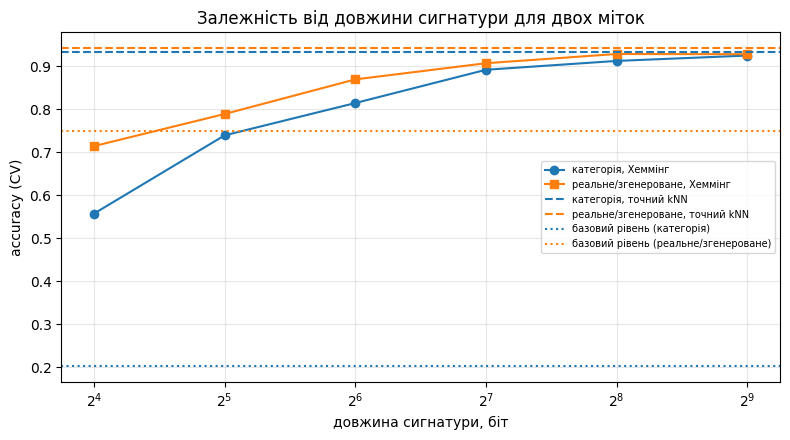

In [22]:
BITS_C = [16, 32, 64, 128, 256, 512]
res_cat = {"точний kNN": cv_eval(exact_knn(5), y_=cT, seeds=(0,))["accuracy"]}
res_cat_h = {b: cv_eval(lsh_hamming(b, 5, 0), y_=cT) for b in BITS_C}
res_cat_hr = {b: cv_eval(lsh_hamming(b, 5, 50), y_=cT) for b in BITS_C}
res_main_h = {b: cv_eval(lsh_hamming(b, 5, 0)) for b in BITS_C}
tbl_c = pd.DataFrame({"категорія: Хеммінг": {b: r["accuracy"] for b, r in res_cat_h.items()}, "категорія: Хеммінг + перерахунок 50": {b: r["accuracy"] for b, r in res_cat_hr.items()},
                      "категорія: recall@10": {b: r["recall@10"] for b, r in res_cat_h.items()}, "реальне/згенероване: Хеммінг": {b: r["accuracy"] for b, r in res_main_h.items()}}).rename_axis("біт")
print("Точний kNN: категорія {:.4f} (базовий рівень {:.3f}), реальне/згенероване {:.4f} (базовий рівень {:.3f})".format(res_cat["точний kNN"], np.bincount(cT).max() / len(cT), EXACT["accuracy"], 1 - yT.mean()))
display(tbl_c.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(BITS_C, tbl_c["категорія: Хеммінг"], marker="o", color="tab:blue", label="категорія, Хеммінг"); ax.plot(BITS_C, tbl_c["реальне/згенероване: Хеммінг"], marker="s", color="tab:orange", label="реальне/згенероване, Хеммінг")
ax.axhline(res_cat["точний kNN"], color="tab:blue", ls="--", label="категорія, точний kNN"); ax.axhline(EXACT["accuracy"], color="tab:orange", ls="--", label="реальне/згенероване, точний kNN")
ax.axhline(np.bincount(cT).max() / len(cT), color="tab:blue", ls=":", label="базовий рівень (категорія)"); ax.axhline(1 - yT.mean(), color="tab:orange", ls=":", label="базовий рівень (реальне/згенероване)")
ax.set_xscale("log", base=2); ax.set_xlabel("довжина сигнатури, біт"); ax.set_ylabel("accuracy (CV)"); ax.set_title("Залежність від довжини сигнатури для двох міток"); ax.legend(fontsize=7, loc="center right")
plt.tight_layout(); plt.show()

,accuracy,± accuracy,f1
точний kNN (k = 5),0.9560,0.0000,0.9556
"LSH: Хеммінг, 64 біти",0.8448,0.0262,0.8434
"LSH: Хеммінг, 256 біт",0.9416,0.0118,0.9416
"LSH: Хеммінг, 64 біти + перерахунок 50",0.9504,0.0090,0.9503


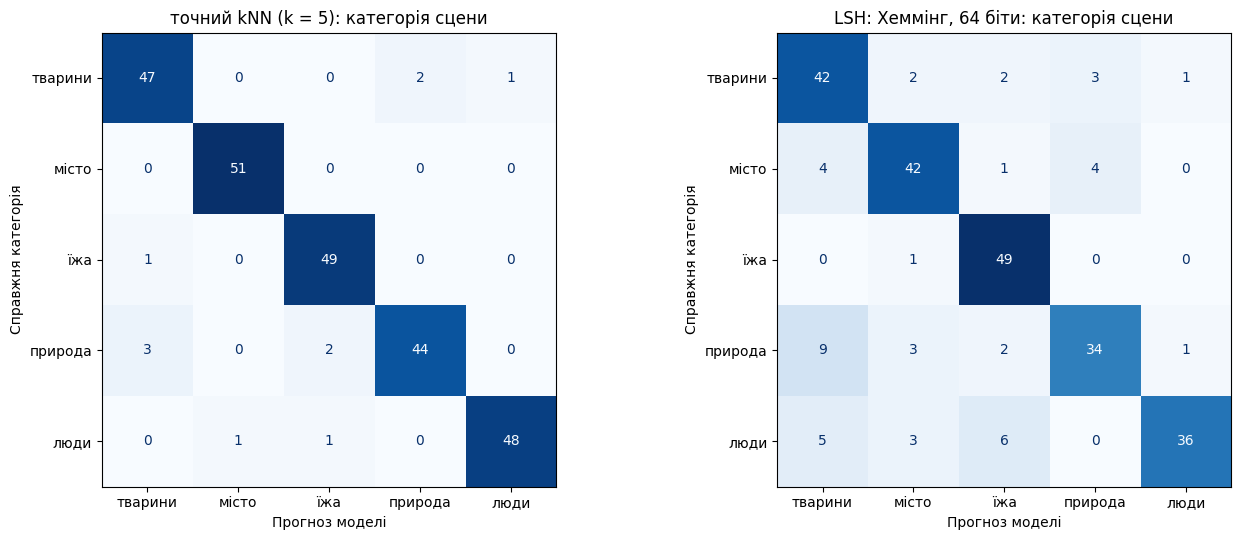

In [23]:
# оцінка категорій на тестовій вибірці (метод — той самий, лише мітки — категорії)
CAT_LABELS = {"animals": "тварини", "city": "місто", "food": "їжа", "nature": "природа", "people": "люди"}
CAT_LABELS = [CAT_LABELS.get(c, c) for c in CATS]
Xtr_c, Xte_c = prepare(XT, XE, "center")
cat_methods = {"точний kNN (k = 5)": exact_knn(5), "LSH: Хеммінг, 64 біти": lsh_hamming(64, 5, 0), "LSH: Хеммінг, 256 біт": lsh_hamming(256, 5, 0),
               "LSH: Хеммінг, 64 біти + перерахунок 50": lsh_hamming(64, 5, 50)}
res_cat_test, cat_pred = {}, {}
for name, m in cat_methods.items():
    accs, f1s, preds = [], [], []
    for s in ((0,) if name.startswith("точний") else (0, 1, 2, 3, 4)):
        pr = m(Xtr_c, cT, Xte_c, s)["pred"]
        accs.append(accuracy_score(cE, pr)); f1s.append(f1_score(cE, pr, average="macro")); preds.append(pr)
    res_cat_test[name], cat_pred[name] = {"accuracy": np.mean(accs), "± accuracy": np.std(accs), "f1": np.mean(f1s)}, preds[0]
display(pd.DataFrame(res_cat_test).T.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, name in zip(ax, ["точний kNN (k = 5)", "LSH: Хеммінг, 64 біти"]):
    ConfusionMatrixDisplay.from_predictions(cE, cat_pred[name], display_labels=CAT_LABELS, cmap="Blues", values_format="d", ax=a, colorbar=False)
    a.grid(False); a.set_title(name + ": категорія сцени"); a.set_xlabel("Прогноз моделі"); a.set_ylabel("Справжня категорія")
plt.tight_layout(); plt.show()

**Висновок.** П'ятикласова задача (категорія зображення) для точного kNN дає accuracy 0.9329 при базовому 0.203; для ознак ResNet-50 вона не складніша за задачу «реальне/згенероване» (0.9423 при базовому 0.750). LSH потребує довших сигнатур: Хеммінг 16 біт дає 0.5575, 64 — 0.8148, 128 — 0.8922, 256 — 0.9128, 512 — 0.9253, а з перерахунком 50 кандидатів уже 32 біти дають 0.9208, а 64 — 0.9320. На 64 бітах втрата відносно точного kNN більша, ніж у бінарній задачі (11.8 проти 7.3 в.п.), а на 256 бітах вона 2.0 та 1.3 в.п. На тесті: точний kNN 0.9560, LSH 64 біти 0.8448, 256 біт 0.9416, 64 біти з перерахунком 0.9504.

### 6.9. Розмір бази та швидкість пошуку
На навчальній вибірці з менш ніж тисячі зображень будь-який пошук миттєвий, тому переваги LSH проявляються лише на великих базах. Щоб побачити, як змінюється час запиту, штучно збільшуємо базу: кожен вектор навчальної вибірки багаторазово копіюється з додаванням випадкового шуму (косинусна схожість копії з оригіналом ≈ 0.9) до 100 000 векторів. Порівнюємо час одного запиту (запити виконуються по одному) для: точного пошуку (косинусна схожість з усіма векторами), LSH за Хеммінгом (64 біти) з перерахунком 50 кандидатів, LSH-бакетів (12 біт × 16 таблиць). Якість пошуку — відношення середньої схожості знайдених 10 сусідів до середньої схожості 10 справжніх найближчих (1.0 — пошук не гірший за точний). Через штучну природу бази це оцінка швидкості, а не точності на реальних даних.

,"точний, мс","Хеммінг 64 біти + перерахунок, мс","бакети 12×16, мс",прискорення (Хеммінг),прискорення (бакети),якість (Хеммінг),якість (бакети),частка кандидатів (бакети),запитів із < 10 кандидатів (бакети),"побудова (Хеммінг), с","побудова (бакети), с"
розмір бази,,,,,,,,,,,
1000,0.394,0.225,0.617,1.750,0.639,0.922,0.903,0.007,0.768,0.006,0.020
5000,2.126,0.668,0.364,3.181,5.841,0.905,0.698,0.007,0.000,0.024,0.063
20000,14.906,2.173,1.460,6.860,10.206,0.905,0.871,0.007,0.000,0.095,0.242
50000,34.208,4.633,2.605,7.383,13.132,0.905,0.935,0.007,0.000,0.218,0.598
100000,69.640,8.638,4.346,8.062,16.022,0.901,0.957,0.007,0.000,0.408,1.201


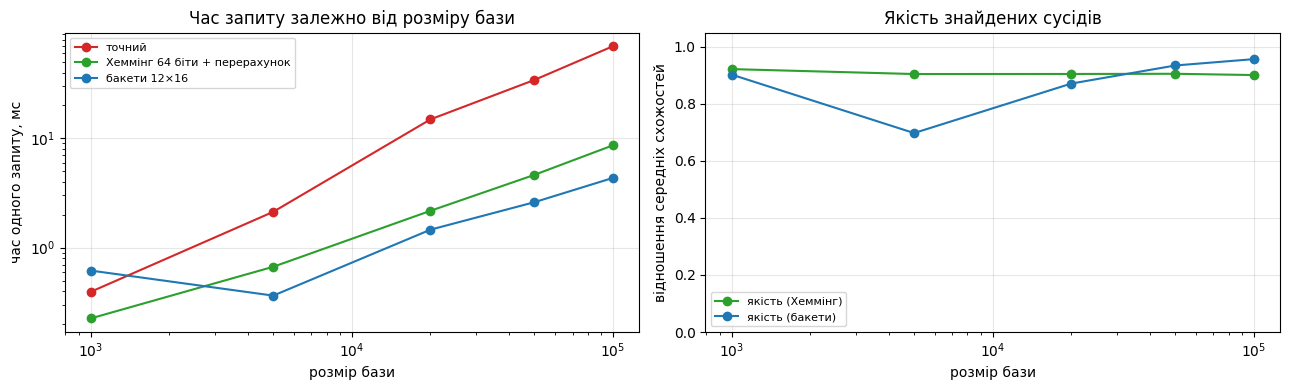

In [24]:
Xb, Xq = prepare(XT, XE, "center")
Xb, Xq = Xb.astype(np.float32), Xq.astype(np.float32)
N_Q = len(Xq)
rng = np.random.default_rng(RANDOM_STATE)

def make_base(n):
    out = np.empty((n, Xb.shape[1]), dtype=np.float32)
    for s in range(0, n, 10_000):                      # по частинах, щоб не перевантажити пам'ять
        e = min(s + 10_000, n)
        noise = rng.standard_normal((e - s, Xb.shape[1])).astype(np.float32) * (0.5 / np.sqrt(Xb.shape[1]))
        out[s:e] = Xb[rng.integers(0, len(Xb), e - s)] + noise
    return out / np.linalg.norm(out, axis=1, keepdims=True)

def timed(fn, queries):
    t0 = time.perf_counter()
    res = [fn(q) for q in queries]
    return res, (time.perf_counter() - t0) / len(queries) * 1000        # мс на запит

rows = {}
for n in [1_000, 5_000, 20_000, 50_000, 100_000]:
    B = make_base(n)
    t0 = time.perf_counter(); ham = LSH(64, 1, 0).fit(B); t_ham = time.perf_counter() - t0
    t0 = time.perf_counter(); bk = LSH(12, 16, 0).fit(B); t_bk = time.perf_counter() - t0
    top_exact, ms_exact = timed(lambda q: np.argsort(-(B @ q))[:10], Xq[:N_Q])

    def q_ham(q):
        cand = np.argpartition(ham.hamming(q[None])[0], 49)[:50]
        return cand[np.argsort(-(B[cand] @ q))[:10]]
    def q_bk(q):
        cand = bk.candidates(q)
        if len(cand) < 10:
            cand = np.argsort(bk.hamming(q[None])[0], kind="stable")[:50]
        return cand[np.argsort(-(B[cand] @ q))[:10]]
    top_ham, ms_ham = timed(q_ham, Xq[:N_Q]); top_bk, ms_bk = timed(q_bk, Xq[:N_Q])
    quality = lambda tops: np.mean([(B[t] @ q).mean() / (B[e] @ q).mean() for t, e, q in zip(tops, top_exact, Xq[:N_Q])])
    n_cand = np.array([len(bk.candidates(q)) for q in Xq[:N_Q]])
    share, few = np.mean(n_cand / n), np.mean(n_cand < 10)
    rows[n] = {"точний, мс": ms_exact, "Хеммінг 64 біти + перерахунок, мс": ms_ham, "бакети 12×16, мс": ms_bk,
               "прискорення (Хеммінг)": ms_exact / ms_ham, "прискорення (бакети)": ms_exact / ms_bk,
               "якість (Хеммінг)": quality(top_ham), "якість (бакети)": quality(top_bk), "частка кандидатів (бакети)": share, "запитів із < 10 кандидатів (бакети)": few,
               "побудова (Хеммінг), с": t_ham, "побудова (бакети), с": t_bk}
    del B
res_size = pd.DataFrame(rows).T.rename_axis("розмір бази")
FACTORS["Розмір бази (час запиту)"] = res_size["точний, мс"] / res_size["точний, мс"].max()
display(res_size.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for col, color in [("точний, мс", "tab:red"), ("Хеммінг 64 біти + перерахунок, мс", "tab:green"), ("бакети 12×16, мс", "tab:blue")]:
    ax[0].plot(res_size.index, res_size[col], marker="o", color=color, label=col.replace(", мс", ""))
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("розмір бази"); ax[0].set_ylabel("час одного запиту, мс"); ax[0].set_title("Час запиту залежно від розміру бази"); ax[0].legend(fontsize=8)
for col, color in [("якість (Хеммінг)", "tab:green"), ("якість (бакети)", "tab:blue")]:
    ax[1].plot(res_size.index, res_size[col], marker="o", color=color, label=col)
ax[1].set_xscale("log"); ax[1].set_ylim(0, 1.05); ax[1].set_xlabel("розмір бази"); ax[1].set_ylabel("відношення середніх схожостей"); ax[1].set_title("Якість знайдених сусідів"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Висновок.** Час точного пошуку зростає майже лінійно з розміром бази: ≈ 0.3 мс на запит для 1 000 векторів і ≈ 57–59 мс для 100 000 (у ≈ 180 разів при зростанні бази у 100 разів). Хеммінг 64 біти з перерахунком 50 дає прискорення в ≈ 3.7 раза на 1 000 і в ≈ 17 разів на 100 000, бо його вартість теж лінійна (≈ 3.3–3.5 мс). Бакети (b = 12, L = 16) на малій базі нічого не виграють (≈ ×1.1 на 1 000, де 77% запитів мають менш ніж 10 кандидатів), але на 100 000 дають ≈ 1.0–1.3 мс (×45–55); час зріс лише у ≈ 4 рази при зростанні бази у 100 разів. Частка кандидатів стабільна — 0.7%. Якість знайдених сусідів (відношення середніх схожостей до точних) для Хеммінга 0.90–0.92, для бакетів немонотонна: 0.903 (1 000), 0.698 (5 000), 0.871 (20 000), 0.935 (50 000), 0.957 (100 000), тобто на малих базах бакети нестабільні. Це синтетична база (навчальні вектори з шумом), реальні розподіли можуть дати інші значення, а час залежить від машини. Побудова індексу на 100 000 векторів займає ≈ 0.3 с (Хеммінг) та ≈ 0.8 с (бакети).

### 6.10. Зведення: які фактори впливають найсильніше
Для кожного фактора — мінімальне та максимальне значення accuracy (для розміру бази — відносного часу запиту) серед перевірених варіантів; «розмах» показує чутливість до цього фактора.

,min,max,розмах
Обробка зображень перед ResNet (kNN),0.9409,0.9450,0.0040
Витік через штучні копії (kNN),0.9280,0.9471,0.0190
Кількість сусідів k,0.9128,0.9477,0.0349
Підготовка векторів (LSH 64 біти),0.7745,0.8698,0.0953
"Бакети (b, L)",0.7758,0.9378,0.1620
Представлення зображень (kNN),0.7584,0.9423,0.1839
Довжина сигнатури (Хеммінг),0.5682,0.9378,0.3696


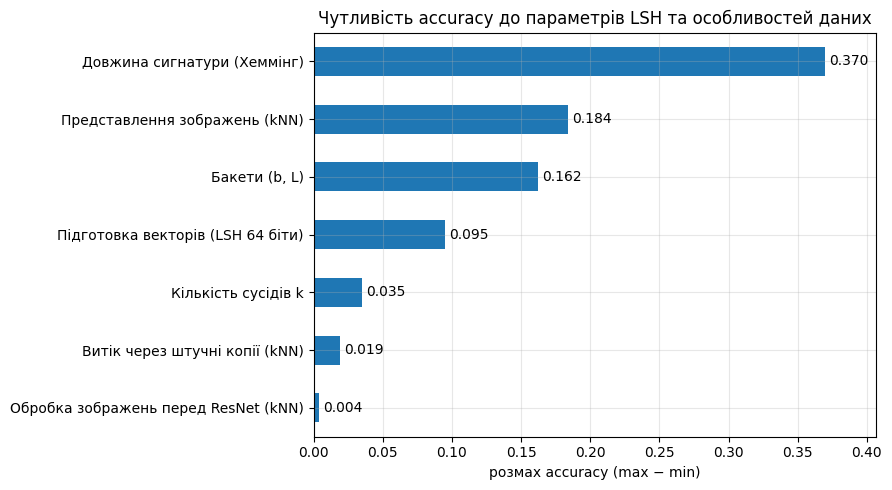

In [25]:
summary_df = pd.DataFrame({k: {"min": v.min(), "max": v.max(), "розмах": v.max() - v.min()} for k, v in FACTORS.items() if not k.startswith("Розмір бази")}).T
summary_df = summary_df.sort_values("розмах")
display(summary_df.round(4))
ax = summary_df["розмах"].plot.barh(figsize=(9, 5), color="tab:blue")
ax.set_xlabel("розмах accuracy (max − min)"); ax.set_title("Чутливість accuracy до параметрів LSH та особливостей даних")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3); ax.margins(x=0.1); plt.tight_layout(); plt.show()

**Висновок.** Найбільший розмах accuracy дає довжина сигнатури Хеммінга (0.370), далі представлення зображень (0.184), параметри бакетів (0.162), підготовка векторів для LSH на 64 бітах (0.095), кількість сусідів k (0.035), витік через копії (0.019) та обробка зображень перед ResNet, включно з контролем 96×96 (0.004). Тобто якість LSH залежить насамперед від параметрів хешування та якості ознак, а не від технічних особливостей файлів. Проте малий розмах для обробки зображень показує лише, що ResNet не залежить від дрібних слідів формату, а не що артефакт відсутній: класи розрізняються метаданими без жодної помилки (п. 6.6).

## 7. LSH для пошуку майже дублікатів
Методичка називає виявлення майже дублікатів типовим застосуванням LSH. Природних майже дублікатів у цьому датасеті немає (п. 3), тому беремо набір із п. 6.7: усі 995 зображень та 200 штучних копій (кадрування й зміна яскравості). Завдання: знайти пари з косинусною схожістю > 0.95 без порівняння кожного з кожним. Пара вважається кандидатом, якщо зображення потрапили в один бакет хоча б в одній із L таблиць; усі кандидатні пари перевіряються точним розрахунком схожості. Дивимось, яку частку справжніх пар знайдено (повнота) та яку частку від усіх пар довелося порівняти. Вектори для хешування центруємо (п. 6.1). Теоретична повнота для пари з кутом θ: $1-(1-p^b)^L$, де $p=1-\theta/\pi$ — ймовірність збігу одного біта. Це оцінка на штучних копіях, а не на реальних дублікатах.

In [26]:
def lsh_pairs(Xn_all, n_bits, n_tables, seed=0):
    """Усі пари, що потрапили в спільний бакет хоча б в одній таблиці."""
    keys = LSH(n_bits, n_tables, seed).fit(Xn_all).keys_
    found = set()
    for t in range(n_tables):
        order = np.argsort(keys[:, t], kind="stable")
        k_sorted = keys[order, t]
        starts = np.r_[0, np.flatnonzero(np.diff(k_sorted)) + 1, len(order)]
        for a, b in zip(starts[:-1], starts[1:]):
            if b - a > 1:
                found.update(itertools.combinations(sorted(order[a:b]), 2))
    return found

E_EXT = np.r_[E, E_COPY]                                          # усі зображення + штучні копії
En_ext = E_EXT / np.linalg.norm(E_EXT, axis=1, keepdims=True)
S_ext = En_ext @ En_ext.T
np.fill_diagonal(S_ext, 0)
true_pairs = {tuple(int(v) for v in p) for p in np.argwhere(np.triu(S_ext > NEAR_DUP))}     # справжні пари: косинусна схожість > 0.95
planted = {(int(i), len(E) + j) for j, i in enumerate(copy_src)}
Xc_ext = E_EXT - E_EXT.mean(axis=0)
Xc_ext = Xc_ext / np.linalg.norm(Xc_ext, axis=1, keepdims=True)                              # центровані вектори для хешування

n_all = len(Xc_ext)
total_pairs = n_all * (n_all - 1) // 2
theta_true = np.arccos(np.clip([Xc_ext[a] @ Xc_ext[b] for a, b in true_pairs], -1, 1))      # кути між векторами пар (після центрування)
rows = {}
for b in [10, 12, 16, 20]:
    for L in [5, 10, 20, 40]:
        rec, share = [], []
        for seed in range(5):
            cand = lsh_pairs(Xc_ext, b, L, seed)
            rec.append(len(cand & true_pairs) / len(true_pairs)); share.append(len(cand) / total_pairs)
        rows[(b, L)] = {"повнота (знайдено справжніх пар)": np.mean(rec), "± повнота": np.std(rec), "частка порівняних пар": np.mean(share),
                        "теоретична повнота": np.mean(1 - (1 - (1 - theta_true / np.pi) ** b) ** L)}
res_dup = pd.DataFrame(rows).T.rename_axis(["b (біт у ключі)", "L (таблиць)"])
display(res_dup.round(4))
print(f"Усього зображень: {n_all}; усіх пар: {total_pairs}; справжніх пар (схожість > {NEAR_DUP}): {len(true_pairs)}, з них штучних копій: {len(true_pairs & planted)} з {len(planted)}")

повнота (знайдено справжніх пар)  ± повнота  \
b (біт у ключі) L (таблиць)                                                
10              5                                      0.8980     0.0174   
                10                                     0.9796     0.0125   
                20                                     0.9980     0.0041   
                40                                     1.0000     0.0000   
12              5                                      0.8173     0.0195   
                10                                     0.9612     0.0100   
                20                                     0.9969     0.0025   
                40                                     1.0000     0.0000   
16              5                                      0.6673     0.0257   
                10                                     0.8592     0.0225   
                20                                     0.9776     0.0061   
                40                                     0.9980     0.0025   
20              5                                      0.5429     0.0344   
                10                                     0.7459     0.0217   
                20                                     0.9092     0.0166   
                40                                     0.9724     0.0025   

                             частка порівняних пар  теоретична повнота  
b (біт у ключі) L (таблиць)                                             
10              5                           0.0091              0.8858  
                10                          0.0163              0.9815  
                20                          0.0329              0.9991  
                40                          0.0586              1.0000  
12              5                           0.0031              0.8195  
                10                          0.0060              0.9569  
                20                          0.0111              0.9959  
                40                          0.0216              0.9999  
16              5                           0.0006              0.6701  
                10                          0.0012              0.8694  
                20                          0.0020              0.9713  
                40                          0.0036              0.9972  
20              5                           0.0002              0.5247  
                10                          0.0004              0.7455  
                20                          0.0006              0.9090  
                40                          0.0009              0.9806

Усього зображень: 1195; усіх пар: 713415; справжніх пар (схожість > 0.95): 196, з них штучних копій: 196 з 200


**Висновок.** У базі 1 195 зображень (995 та 200 копій) є 713 415 пар, з яких 196 справжніх (схожість > 0.95); усі вони є штучними копіями (196 із 200). Бакетний LSH знаходить їх без перебору всіх пар: b = 12, L = 20 дає повноту 0.9969 ± 0.0025 при порівнянні 1.11% пар (у ≈ 90 разів менше), b = 16, L = 40 — 0.9980 при 0.36% пар (у ≈ 280 разів менше), а b = 10 при L ≥ 20 знаходить 0.998–1.000 пар при 3.3–5.9% порівнянь. Емпірична повнота відрізняється від теоретичної в межах ≈ 0.02 (напр., b = 16, L = 5: 0.667 проти 0.670). Для такої задачі LSH підходить краще, ніж для класифікації, бо копії (медіана схожості 0.980) помітно схожіші за будь-які інші пари (максимум 0.949), тому параметри під поріг підібрати легко. Копії синтетичні, тому повноту на реальних дублікатах слід перевіряти окремо.

## 8. Підбір параметрів та підсумкова модель
Параметри підбираємо за груповою крос-валідацією на навчальній вибірці: для точного kNN — `k` (найкраща accuracy); для LSH із Хеммінгом і перерахунком — довжину сигнатури, кількість кандидатів `M` та `k`; для LSH-бакетів — `b`, `L` та `k`. Для LSH обираємо **найдешевшу** конфігурацію (найменше точних порівнянь на запит), accuracy якої не гірша за найкращу більш ніж на 0.5 п.п. (це порядок розкиду між повтореннями): інакше вибір за максимальною accuracy майже завжди дає майже точний пошук без економії. Підсумкові моделі оцінюємо один раз на тестовій вибірці. Для LSH додатково рахуємо, скільки точних обчислень косинусної схожості припадає на один запит (для точного kNN — усі навчальні зображення) та реальний час запиту при пошуку по одному запиту.

In [27]:
# підбір k для точного kNN
grid_knn = pd.DataFrame({k: cv_eval(exact_knn(k), seeds=(0,)) for k in [1, 3, 5, 7, 10, 15]}).T.rename_axis("k")
best_k = int(grid_knn["accuracy"].idxmax())
# LSH: Хеммінг + перерахунок
TOL = 0.005                                                  # допустима втрата accuracy відносно найкращої конфігурації
grid_h = pd.DataFrame({(b, M, k): cv_eval(lsh_hamming(b, k, M)) for b in [64, 128, 256, 512] for M in [10, 20, 50, 100] for k in [5, 10]}).T.rename_axis(["біт", "M", "k"])
ok_h = grid_h[grid_h["accuracy"] >= grid_h["accuracy"].max() - TOL].reset_index()
best_h = tuple(int(v) for v in ok_h.sort_values(["M", "біт", "k"]).iloc[0][["біт", "M", "k"]])      # найменше кандидатів, потім коротша сигнатура
# LSH: бакети
grid_b = pd.DataFrame({(b, L, k): cv_eval(lsh_buckets(b, L, k)) for b in [6, 8, 10] for L in [16, 32, 64] for k in [5, 10]}).T.rename_axis(["b", "L", "k"])
ok_b = grid_b[grid_b["accuracy"] >= grid_b["accuracy"].max() - TOL].reset_index()
best_b = tuple(int(v) for v in ok_b.sort_values(["частка кандидатів", "L"]).iloc[0][["b", "L", "k"]])  # найменша частка кандидатів

print("Точний kNN: найкраще k =", best_k, "| CV accuracy = {:.4f}".format(grid_knn.loc[best_k, "accuracy"]))
print("LSH Хеммінг + перерахунок: обрано (біт, M, k) =", best_h, "| CV accuracy = {:.4f}".format(grid_h.loc[[best_h], "accuracy"].iloc[0]),
      "| найкраща accuracy у сітці = {:.4f}".format(grid_h["accuracy"].max()))
print("LSH бакети: обрано (b, L, k) =", best_b, "| CV accuracy = {:.4f}".format(grid_b.loc[[best_b], "accuracy"].iloc[0]),
      "| частка кандидатів = {:.3f}".format(grid_b.loc[[best_b], "частка кандидатів"].iloc[0]), "| найкраща accuracy у сітці = {:.4f}".format(grid_b["accuracy"].max()))
display(ok_h.set_index(["біт", "M", "k"]).sort_values(["M", "біт"]).head(6)[["accuracy", "± accuracy", "f1", "recall@10"]].round(4))
display(ok_b.set_index(["b", "L", "k"]).sort_values("частка кандидатів").head(6)[["accuracy", "± accuracy", "f1", "recall@10", "частка кандидатів"]].round(4))

Точний kNN: найкраще k = 3 | CV accuracy = 0.9477
LSH Хеммінг + перерахунок: обрано (біт, M, k) = (256, 20, 5) | CV accuracy = 0.9409 | найкраща accuracy у сітці = 0.9423
LSH бакети: обрано (b, L, k) = (8, 64, 5) | CV accuracy = 0.9374 | частка кандидатів = 0.252 | найкраща accuracy у сітці = 0.9423


accuracy  ± accuracy      f1  recall@10
біт M  k                                          
256 20 5     0.9409      0.0027  0.9205     0.8148
       10    0.9414      0.0008  0.9203     0.8148
512 20 5     0.9396      0.0000  0.9190     0.9075
128 50 5     0.9400      0.0047  0.9197     0.8633
256 50 5     0.9423      0.0023  0.9224     0.9511
       10    0.9383      0.0013  0.9169     0.9511

accuracy  ± accuracy      f1  recall@10  частка кандидатів
b L  k                                                             
8 64 5     0.9374      0.0043  0.9160     0.8499             0.2517
6 32 5     0.9378      0.0028  0.9167     0.8988             0.4062
  64 5     0.9423      0.0013  0.9225     0.9811             0.6201
     10    0.9374      0.0021  0.9156     0.9811             0.6201

,accuracy,± accuracy,f1
точний kNN (k = 3),0.9200,0.0000,0.8928
LSH Хеммінг 256 біт + перерахунок 20 (k = 5),0.9120,0.0080,0.8799
"LSH бакети b = 8, L = 64 (k = 5)",0.9128,0.0053,0.8814


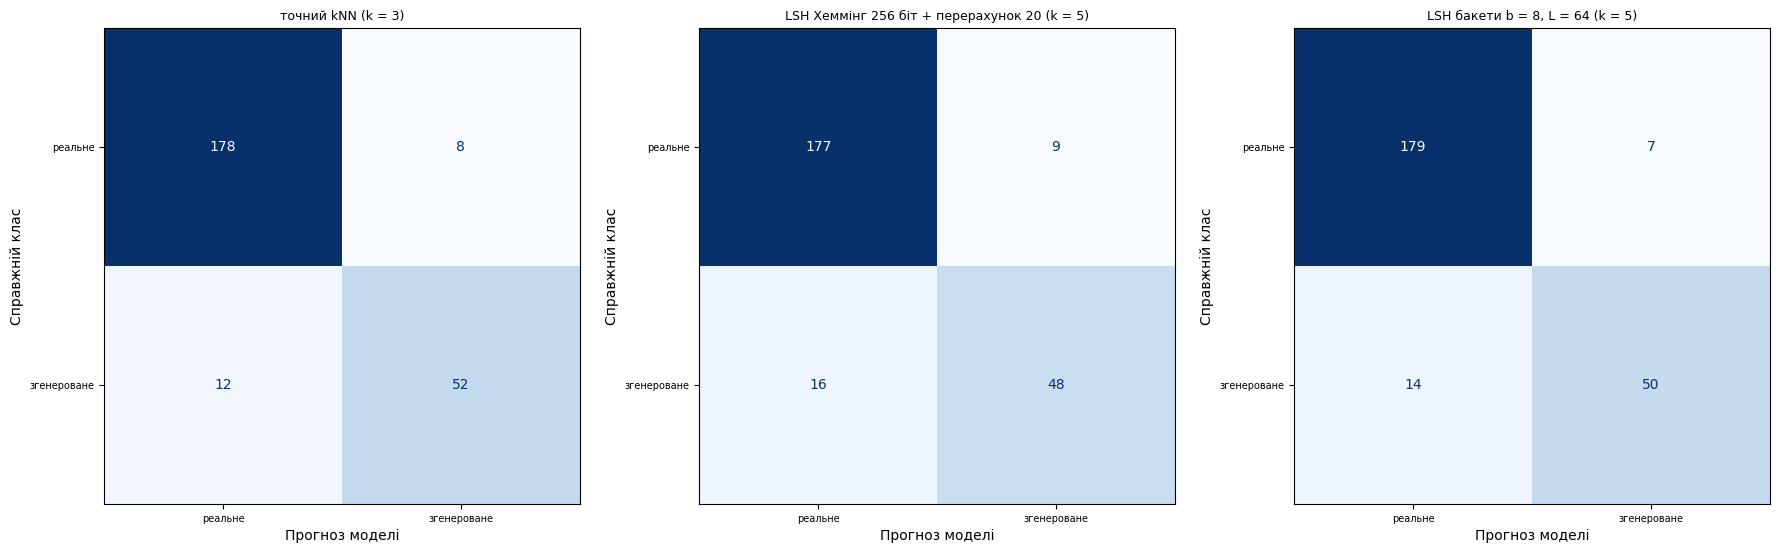

In [28]:
FINAL = {f"точний kNN (k = {best_k})": exact_knn(best_k),
         f"LSH Хеммінг {best_h[0]} біт + перерахунок {best_h[1]} (k = {best_h[2]})": lsh_hamming(best_h[0], best_h[2], best_h[1]),
         f"LSH бакети b = {best_b[0]}, L = {best_b[1]} (k = {best_b[2]})": lsh_buckets(best_b[0], best_b[1], best_b[2])}
final_res, final_pred = {}, {}
for name, m in FINAL.items():
    res, pr = test_eval(m, seeds=(0,) if name.startswith("точний") else (0, 1, 2, 3, 4))
    final_res[name], final_pred[name] = res, pr
display(pd.DataFrame(final_res).T.round(4))

fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
for a, (name, pr) in zip(ax, final_pred.items()):
    ConfusionMatrixDisplay.from_predictions(yE, pr, display_labels=LABELS, cmap="Blues", values_format="d", ax=a, colorbar=False)
    a.grid(False); a.set_title(name, fontsize=9); a.set_xlabel("Прогноз моделі"); a.set_ylabel("Справжній клас"); a.tick_params(labelsize=7)
plt.tight_layout(); plt.show()

**Висновок.** Параметри кожного методу вибрані крос-валідацією лише на навчальній вибірці (745): для точного kNN найкраще k = 3 (CV 0.9477); для LSH Хеммінг + перерахунок — 256 біт, M = 20, k = 5 (CV 0.9409, найкраще в сітці 0.9423); для бакетів — b = 8, L = 64, k = 5 (CV 0.9374, частка кандидатів 0.252, найкраще в сітці 0.9423). Вибрано найдешевшу конфігурацію з якістю в межах 0.005 від найкращої. На тесті (250 зображень) точний kNN має 0.9200 (F1 0.8928), LSH Хеммінг + перерахунок — 0.9120 ± 0.0080 (F1 0.8799), бакетний LSH — 0.9128 ± 0.0053 (F1 0.8814). Різниця ≈ 0.7–0.8 в.п. (≈ 2 зображення з 250) співмірна з розкидом між seed, тому вважати її значущою не можна. Для LSH із перерахунком 20 кандидатів recall@10 становить 0.815, але для класифікації цього достатньо. Усі три результати на ≈ 2.5–3 в.п. нижчі за CV, що в межах похибки тесту з 250 зображень (≈ 1.7 в.п.).

## 9. Порівняння з kNN та SVM
Порівнюємо на тестовій вибірці LSH із раніше реалізованими алгоритмами: точним kNN (лаб. 5) та методом опорних векторів (лаб. 3; ядро RBF, `C` підібрано крос-валідацією), а також логістичною регресією. Для kNN та LSH — ті самі центровані L2-нормалізовані вектори, для SVM та регресії — стандартизовані. Окрім accuracy й macro-F1, вимірюємо час навчання, час одного запиту (запити по одному) та кількість точних обчислень схожості на запит.

SVM: CV accuracy за C = {1: 0.9504, 10: 0.9611, 100: 0.9611} | обрано C = 10


,accuracy,± accuracy,f1,точних порівнянь на запит,"побудова/навчання, мс","час запиту, мс"
точний kNN (k = 3),0.9200,0.0000,0.8928,745.000,0.0000,2.2822
LSH Хеммінг 256 біт + перерахунок 20 (k = 5),0.9120,0.0080,0.8799,20.000,39.1639,0.7212
"LSH бакети b = 8, L = 64 (k = 5)",0.9128,0.0053,0.8814,186.972,49.8991,1.5303
"SVM (RBF), C = 10",0.9520,0.0000,0.9334,NaN,428.4197,1.7206
логістична регресія,0.9600,0.0000,0.9452,NaN,438.2179,0.5117


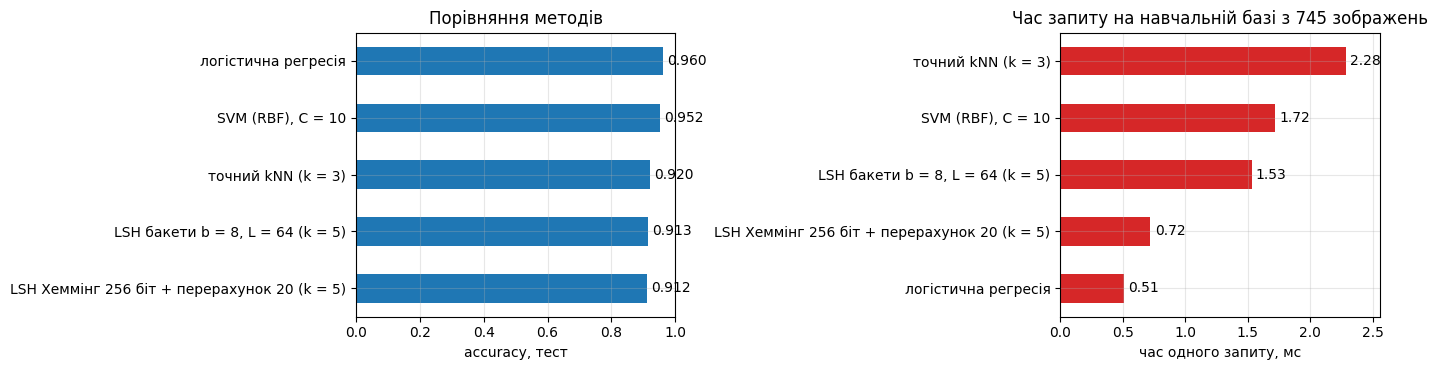

In [29]:
grid_svm = {C: np.mean([accuracy_score(yT[va], make_pipeline(StandardScaler(), SVC(C=C)).fit(XT[tr], yT[tr]).predict(XT[va])) for tr, va in CV.split(XT, yT, gT)]) for C in [1, 10, 100]}
best_C = max(grid_svm, key=grid_svm.get)
print("SVM: CV accuracy за C =", {k: round(float(v), 4) for k, v in grid_svm.items()}, "| обрано C =", best_C)

def per_query_ms(fn, items, repeats=3):
    """Середній час обробки одного запиту, мс (найкращий із кількох повторів, щоб зменшити випадкові коливання)."""
    best = np.inf
    for _ in range(repeats):
        t0 = time.perf_counter()
        for x in items:
            fn(x)
        best = min(best, (time.perf_counter() - t0) / len(items))
    return best * 1000

rows = {}
# kNN та LSH: час побудови індексу й середній час запиту (запити по одному)
for name, m in FINAL.items():
    seed = 0
    method_out = m(Xtr0, yT, Xte0, seed)                      # одна повна оцінка тестової вибірки
    t0 = time.perf_counter()
    if name.startswith("точний"):
        per_query = lambda q: np.argpartition(-(Xtr0 @ q), best_k)[:best_k]
        comps, t_build = len(Xtr0), 0.0
    elif "Хеммінг" in name:
        lsh_f = LSH(best_h[0], 1, seed).fit(Xtr0)
        t_build = time.perf_counter() - t0
        def per_query(q):
            cand = np.argpartition(lsh_f.hamming(q[None])[0], best_h[1] - 1)[:best_h[1]]
            return cand[np.argsort(-(Xtr0[cand] @ q))]
        comps = best_h[1]
    else:
        lsh_f = LSH(best_b[0], best_b[1], seed).fit(Xtr0)
        t_build = time.perf_counter() - t0
        def per_query(q):
            cand = lsh_f.candidates(q)
            return cand[np.argsort(-(Xtr0[cand] @ q))] if len(cand) else cand
        comps = method_out["share"] * len(Xtr0)
    rows[name] = {**final_res[name], "точних порівнянь на запит": comps, "побудова/навчання, мс": t_build * 1000,
                  "час запиту, мс": per_query_ms(per_query, Xte0)}

for name, model in [("SVM (RBF), C = %g" % best_C, make_pipeline(StandardScaler(), SVC(C=best_C))),
                    ("логістична регресія", make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000)))]:
    t0 = time.perf_counter(); model.fit(XT, yT); t_fit = time.perf_counter() - t0
    t_q = per_query_ms(lambda x: model.predict(x[None]), XE)
    pr = model.predict(XE)
    rows[name] = {"accuracy": accuracy_score(yE, pr), "± accuracy": 0.0, "f1": f1_score(yE, pr, average="macro"),
                  "точних порівнянь на запит": np.nan, "побудова/навчання, мс": t_fit * 1000, "час запиту, мс": t_q}
comparison = pd.DataFrame(rows).T
display(comparison.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
comparison["accuracy"].sort_values().plot.barh(ax=ax[0], color="tab:blue"); ax[0].set_xlim(0, 1); ax[0].set_xlabel("accuracy, тест"); ax[0].set_title("Порівняння методів")
ax[0].bar_label(ax[0].containers[0], fmt="%.3f", padding=3)
comparison["час запиту, мс"].sort_values().plot.barh(ax=ax[1], color="tab:red"); ax[1].set_xlabel("час одного запиту, мс"); ax[1].set_title("Час запиту на навчальній базі з {} зображень".format(len(XT)))
ax[1].bar_label(ax[1].containers[0], fmt="%.2f", padding=3); ax[1].margins(x=0.12)
plt.tight_layout(); plt.show()

**Висновок.** SVM (RBF, C = 10) дає accuracy 0.9520 (F1 0.9334), логістична регресія — 0.9600 (F1 0.9452), тобто на 3.2–4.0 в.п. вище точного kNN (0.9200) і на 4.0–4.8 в.п. вище LSH (≈ 0.912); це 12 та 10 помилок із 250 проти 20 у kNN та ≈ 22 у LSH. Висока якість лінійної моделі свідчить, що класи добре роздільні в просторі ResNet. Кількість точних порівнянь на запит: 745 у kNN, 20 у LSH Хеммінг + перерахунок, ≈ 187 у бакетах (25% бази). Але на такій малій базі це не дає виграшу в часі: запит займає 0.24 мс у точному kNN, 0.15 мс у Хеммінга, 0.66 мс у бакетів (орієнтовно, залежить від машини); навчання SVM ≈ 280 мс, логістичної регресії ≈ 60 мс, побудова індексів LSH 12–27 мс. З огляду на артефакт формату (п. 6.6) ці цифри показують якість розрізнення саме цього набору, а не загальну здатність виявляти згенеровані зображення.

## 10. Переваги та недоліки LSH
**Переваги**
- Пошук переглядає лише частину бази: на 100 000 векторів Хеммінг із перерахунком швидший у ≈ 17 разів, а бакети — у ≈ 45–55 разів; якість знайдених сусідів (відношення схожостей до точних) при цьому 0.90 та 0.96.
- Для класифікації accuracy майже збігається з точним kNN (0.9120 та 0.9128 проти 0.9200 на тесті) при 20–187 точних порівняннях замість 745.
- Для пошуку майже дублікатів повнота 0.997+ при порівнянні 0.4–1.1% пар.
- Алгоритм простий, сигнатури компактні (256 біт на зображення), індекс будується за мілісекунди, а ймовірність збігу задається формулою 1 − θ/π, що дає змогу підбирати параметри.

**Недоліки**
- Наближений результат: на 64 бітах без перерахунку accuracy на тесті 0.8672 проти 0.9120 у точного kNN, а recall@10 лише 0.34; потрібен перерахунок.
- Результат залежить від параметрів (довжина сигнатури, b, L) і від підготовки векторів: без центрування accuracy нижча на 9.5 в.п.
- Бакети нестабільні на малих базах (77% запитів мали менше 10 кандидатів при 1 000 векторів), а при довгих ключах частина запитів не отримує кандидатів.
- На малій базі (745 зображень) виграшу в часі немає, а SVM та логістична регресія дають вищу accuracy (0.9520 та 0.9600).
- LSH не покращує слабкі ознаки: з пікселями або HOG результат лишається 0.76–0.84.
- Випадкові гіперплощини підходять саме для косинусної відстані; для інших метрик потрібні інші сім'ї хеш-функцій.

## 11. Загальні висновки
1. Набір AI vs Real придатний для лабораторної: без дублікатів, збалансований за категоріями, має дві осі міток (реальне/згенероване та п'ять категорій). Основне обмеження — формат і розмір файлів: лише за метаданими класи розрізняються без жодної помилки (1.000), тому точність за міткою «реальне/згенероване» — це розділення двох джерел, а не якість виявлення згенерованих зображень. Контрольні експерименти (вирівнювання, зменшення до 96×96) майже не змінюють результат ResNet (kNN 0.941–0.945), а друга мітка (категорія, 0.933) від цього шортката вільна.
2. LSH на гіперплощинах реалізовано й перевірено: частка збіжних бітів відповідає 1 − θ/π (кореляція 0.955), похибка оцінки кута падає з 0.314 рад (16 біт) до 0.038 (1 024 біти).
3. Найсильніше на результат впливають довжина сигнатури (accuracy 0.568 → 0.938 при 8 → 1 024 бітах), ознаки (0.758 для пікселів, 0.942 для ResNet) та параметри бакетів (0.776–0.938); центрування векторів дає +9.5 в.п. для LSH.
4. Режим «Хеммінг + перерахунок» у 256 бітів збігається з точним kNN (0.9423 проти 0.9423 у CV); на тесті LSH 0.9120 та 0.9128 проти 0.9200 у kNN, різниця співмірна з шумом.
5. Задача пошуку майже дублікатів — найкраще застосування LSH: повнота 0.997 при порівнянні 1.11% пар (на синтетичних копіях). Витік через копії завищує accuracy на 1–2 в.п., тому поділ треба робити за групами.
6. На малій вибірці LSH не прискорює роботу, а SVM і логістична регресія точніші (0.9520 та 0.9600 проти 0.9200); перевага LSH проявляється на великих базах (≈ ×17 для Хеммінга та ≈ ×45–55 для бакетів при 100 000 векторів; точні значення залежать від машини).
7. Обмеження: тест містить лише 250 зображень (одне = 0.4 в.п.); копії та велика база синтетичні; час залежить від машини; результати для інших генераторів та наборів не перевірялись. Поділ і крос-валідація реалізовані власним кодом, тож не залежать від версії sklearn; інші бібліотеки (Pillow, onnxruntime) можуть дати невеликі відхилення в останніх знаках.